In [1]:
%pip install -q --break-system-packages -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc
import hashlib
import json
import os
import re
import shutil
import time

os.environ["HF_HOME"] = "models/hf"  # must be set before any Hugging Face library is imported

import bm25s
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import Stemmer
import torch
from datasets import Dataset
from mlx_lm import batch_generate, load
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
from sentence_transformers.cross_encoder import CrossEncoder, CrossEncoderTrainer, CrossEncoderTrainingArguments
from sentence_transformers.cross_encoder import losses as cross_encoder_losses
from sentence_transformers.sentence_transformer.training_args import BatchSamplers
from sklearn.model_selection import train_test_split
from tqdm import tqdm
from transformers import TrainerCallback
from transformers.trainer_utils import get_last_checkpoint

SEED = 0
DATA_PATH = "data/data.parquet"
SPLITS_PATH = "data/splits.parquet"
HISTORIES_PATH = "data/histories.parquet"
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "
# First-stage candidates from the screening. Each model uses its own prompts: None = the prompts in its
# sentence-transformers config. Fine-tuning a candidate (BASE_MODEL) uses the same prompts.
FIRST_STAGE_CANDIDATES = {
    "all-MiniLM-L6-v2": ("sentence-transformers/all-MiniLM-L6-v2", None),
    "bge-base-en-v1.5": ("BAAI/bge-base-en-v1.5", {"query": QUERY_PREFIX}),
    "bge-large-en-v1.5": ("BAAI/bge-large-en-v1.5", {"query": QUERY_PREFIX}),
    "mxbai-embed-large-v1": ("mixedbread-ai/mxbai-embed-large-v1", {"query": QUERY_PREFIX}),
    "e5-large-v2": ("intfloat/e5-large-v2", {"query": "query: ", "passage": "passage: "}),
    "snowflake-arctic-embed-l-v2.0": ("Snowflake/snowflake-arctic-embed-l-v2.0", None),
    "Qwen3-Embedding-0.6B": ("Qwen/Qwen3-Embedding-0.6B", None),
}
MAX_LENGTH = 64
WARMUP_RATIO = 0.1
SAVE_STEPS = 250
KEYWORD_SHARE = 0.30  # keyword examples added, as a share of the question examples
OPENING_CAP = 0.10  # no three-word opening may start more than 10% of the questions
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"


def seeded_hash(key):
    return int(hashlib.md5(f"{SEED}:{key}".encode()).hexdigest()[:15], 16)


BLUE = "#2a78d6"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#898781",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.labelcolor": "#52514e",
    "axes.titlelocation": "left", "axes.titlesize": 11,
})
for folder in ["models/checkpoints", "models/trained"]:
    os.makedirs(folder, exist_ok=True)

/Users/adiram/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1124 19:26:03.823000 63860 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
/var/folders/67/5h9frnrs01j1mx2dt92t8r480000gn/T/ipykernel_63860/2259000893.py:18: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses


In [3]:
EXPERIMENT = "baseline"      # results of a single experiment run go to results/experiments/<EXPERIMENT>/
BASE_MODEL = "BAAI/bge-small-en-v1.5"  # the bi-encoder to fine-tune; first-stage-mxbai, first-stage-snowflake
URL_WORDS = False            # url-words
NEGATIVES = "question"       # "question" (current) or "lookalike"; lookalike-negatives
N_NEGATIVES = 1              # lookalike-negatives may raise this
LEARNING_RATE = 2e-5         # train-harder
EPOCHS = 1                   # train-harder
BATCH_SIZE = 128
CACHED_LOSS = False          # train-harder: CachedMultipleNegativesRankingLoss
MINI_BATCH_SIZE = 128        # the cached loss embeds this many texts at a time; lower it for large models
SCORE_CUTOFF = None          # None = run the cutoff selection; or a name like "drop10" to skip it
RUN_FINAL = True             # False = stop after one seed-0 training run and its validation metrics (experiment mode)
TRAIN_SEED = 0               # experiment mode: the training seed (extra seeds of the chosen model)
TRAIN_ROWS = None  # experiments use 50_000
HALF_PRECISION = False  # experiments: True
RERANKER = None  # e.g. "cross-encoder/ms-marco-MiniLM-L-6-v2"; a cross-encoder reorders the look-alike bi-encoder's top k
RERANK_TOP_K = 20  # recommended so far: "cross-encoder/ms-marco-MiniLM-L-12-v2" at k = 10 (validation Recall@1 0.738), not yet robust on keyword queries
RERANK_KEYWORDS = False  # True: the reranker also trains on the keyword-query examples the bi-encoder uses
SCREEN = False  # screening: score first-stage and reranker candidates off the shelf on the validation questions
TEST = False  # step 4: score every condition once on the 2,000 test questions; results go to results/test/

# Saved with every trained model and every validation.json.
SETTINGS = {"EXPERIMENT": EXPERIMENT, "BASE_MODEL": BASE_MODEL, "URL_WORDS": URL_WORDS, "NEGATIVES": NEGATIVES, "N_NEGATIVES": N_NEGATIVES,
            "LEARNING_RATE": LEARNING_RATE, "EPOCHS": EPOCHS, "BATCH_SIZE": BATCH_SIZE, "CACHED_LOSS": CACHED_LOSS,
            "MINI_BATCH_SIZE": MINI_BATCH_SIZE, "SCORE_CUTOFF": SCORE_CUTOFF, "RUN_FINAL": RUN_FINAL, "TRAIN_SEED": TRAIN_SEED,
            "TRAIN_ROWS": TRAIN_ROWS, "HALF_PRECISION": HALF_PRECISION,
            "RERANKER": RERANKER, "RERANK_TOP_K": RERANK_TOP_K, "RERANK_KEYWORDS": RERANK_KEYWORDS, "SCREEN": SCREEN, "TEST": TEST}
# Name of the off-the-shelf model in results; the default keeps its old name.
BASE_NAME = "bge_base" if BASE_MODEL == "BAAI/bge-small-en-v1.5" else BASE_MODEL.split("/")[-1]


In [4]:
# The one place an entry's text is built: the BM25 index, bge encoding, training examples and hard negatives all use it.
def url_words(url):
    # Each run of / . _ - ? = & + becomes one space: "rottentomatoes.com/m/john_wick" -> "rottentomatoes com m john wick".
    return re.sub(r"[/._\-?=&+]+", " ", url).strip()


def make_entry(title, url):
    if URL_WORDS:
        return f"{title} | {url_words(url)}"
    return f"{title} | {url}"


make_entry("Biography", "imdb.com/name/nm0025309/bio")

'Biography | imdb.com/name/nm0025309/bio'

In [5]:
data = pd.read_parquet(DATA_PATH)

if os.path.exists(SPLITS_PATH):
    splits = pd.read_parquet(SPLITS_PATH)
else:
    rest, test_qids = train_test_split(data["qid"], test_size=2_000, random_state=SEED)
    train_qids, validation_qids = train_test_split(rest, test_size=500, random_state=SEED)
    splits = pd.DataFrame({"qid": data["qid"], "split": "train"})
    splits.loc[splits["qid"].isin(validation_qids), "split"] = "validation"
    splits.loc[splits["qid"].isin(test_qids), "split"] = "test"
    splits.to_parquet(SPLITS_PATH, index=False)
print(splits["split"].value_counts().to_string())

split
train         297500
test            2000
validation       500


In [6]:
# The same rules as the Qwen training prompt in data.ipynb. Both are neutral: they allow title words, so BM25 is not
# handicapped by design. Each LLM has its own few-shot examples.
SYSTEM = """You rewrite search-engine queries into questions a person would ask an AI assistant that searches their own browsing history.

You will get the keyword query someone typed and the title and URL of the page they clicked. Imagine that same person days later, trying to find that page again by asking the assistant in plain, everyday words.

Rules:
- Write one complete, grammatical question or request, 6 to 20 words, in casual language. Ask only one thing.
- Refer to the page as something they already saw ("that article", "the recipe I found", "the video I watched"), and vary how you do it.
- Vary how the question starts, as the examples do. Most questions should not start with "Where".
- Keep the main name a person would remember, such as the show, product, person or place, so the page can still be found.
- Name the website only when a person would naturally remember it, like a video on YouTube or a listing on Zillow. Most questions should not name the site.
- When the title is vague, use the URL to work out what the page is about. Names in the URL, like a Wikipedia article name, are fine to use, but never copy ID numbers, codes or file names.
- Use only information in the query, title or URL. Do not invent details like dates, times, prices or reasons.
- Output only the question, with no quotes or explanation."""

# Llama gets its own examples, so its phrasing is not copied from Qwen's. None of these pages is in the dataset.
# Like the rule, most examples do not name the site (2 of 6 do).
LLAMA_EXAMPLES = [
    ("nike running shoes women", "Women's Running Shoes. Nike.com", "nike.com/w/womens-running-shoes",
     "Show me the women's running shoes I was browsing."),
    ("sourdough starter", "How to Make a Sourdough Starter From Scratch", "kingarthurbaking.com/recipes/sourdough-starter-recipe",
     "Can you find the guide I read on how to make a sourdough starter from scratch?"),
    ("w4 form 2019", "About Form W-4", "irs.gov/forms-pubs/about-form-w-4",
     "Which page about the W-4 form was I looking at?"),
    ("intermittent fasting benefits", "Does Intermittent Fasting Work?", "nytimes.com/2019/06/12/well/eat/intermittent-fasting",
     "What did that article say about whether intermittent fasting works?"),
    ("flask python github", "pallets/flask: The Python micro framework for building web applications.", "github.com/pallets/flask",
     "Pull up the Flask repository I had open on GitHub."),
    ("never gonna give you up", "Rick Astley - Never Gonna Give You Up (Official Music Video)", "youtube.com/watch?v=dQw4w9WgXcQ",
     "Find the Rick Astley music video I watched on YouTube."),
]
LLAMA = "mlx-community/Meta-Llama-3.1-8B-Instruct-4bit"  # loaded in the next cell, only if a question is missing


def llama_prompt(query, title, url):
    messages = [{"role": "system", "content": SYSTEM}]
    for q, t, u, answer in LLAMA_EXAMPLES:
        messages.append({"role": "user", "content": f"Query: {q}\nPage title: {t}\nURL: {u}"})
        messages.append({"role": "assistant", "content": answer})
    messages.append({"role": "user", "content": f"Query: {query}\nPage title: {title}\nURL: {url}"})
    prompt = llama_tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
    return llama_tokenizer.encode(prompt, add_special_tokens=False)  # the template already starts with the BOS token

In [7]:
def save(df):
    assert df["qid"].is_unique
    assert df["answer_did"].is_unique
    assert all(did in clicks for did, clicks in zip(df["answer_did"], df["clicked_dids"]))
    assert (df["title"].str.strip() != "").all() and (df["url"].str.strip() != "").all()
    df.to_parquet(DATA_PATH, compression="zstd", index=False)
    print(f"saved {len(df):,} rows, {os.path.getsize(DATA_PATH) / 1e6:.1f} MB")


held_out = data["qid"].isin(splits.loc[splits["split"] != "train", "qid"])
# The prompt's id is saved next to the data; a different prompt writes every validation and test question again.
# It is saved before generating, so an interrupted run resumes instead of starting over.
PROMPT_ID_PATH = "data/llama_prompt_id.txt"
prompt_id = str(seeded_hash(SYSTEM + repr(LLAMA_EXAMPLES)) % 10**8)
saved_id = open(PROMPT_ID_PATH).read().strip() if os.path.exists(PROMPT_ID_PATH) else None
if saved_id != prompt_id:
    print(f"Llama prompt changed ({saved_id} -> {prompt_id}): all validation and test questions are written again")
    data.loc[held_out, ["test_question", "test_score"]] = np.nan
    save(data)
    with open(PROMPT_ID_PATH, "w") as f:
        f.write(prompt_id + "\n")
todo = data.index[held_out & data["test_question"].isna()]
print(f"{held_out.sum():,} validation and test rows, {len(todo):,} still need a Llama question")

if len(todo):
    llama, llama_tokenizer = load(LLAMA)
    for start in tqdm(range(0, len(todo), 500)):
        rows = data.loc[todo[start:start + 500]]
        out = batch_generate(llama, llama_tokenizer, [llama_prompt(r.query, r.title, r.url) for r in rows.itertuples()],
                             max_tokens=40, return_logprobs=True, completion_batch_size=64, prefill_batch_size=64)
        data.loc[rows.index, "test_question"] = [t.strip().split("\n")[0].strip() for t in out.texts]
        data.loc[rows.index, "test_score"] = [sum(lp) / len(lp) if lp else float("nan") for lp in out.logprobs]
        save(data)
    del llama, llama_tokenizer  # free the Mac's memory for training
assert data.loc[held_out, "test_question"].notna().all() and data.loc[~held_out, "test_question"].isna().all()

2,500 validation and test rows, 0 still need a Llama question


Qwen   mean 11.2 words, 100.0% within 6-20 words,  4.4% copy 4+ title words, 0 duplicates
Llama  mean 11.7 words, 100.0% within 6-20 words,  6.1% copy 4+ title words, 0 duplicates
Llama test_score: median -0.413, Qwen train_score: median -0.167
Qwen opening  Qwen %    Llama opening  Llama %
      i need    22.5       what's the     43.5
      i want    15.0         what are     13.5
    what was    13.9        what does      8.6
   where can     9.9           how do      6.2
 i'm looking     4.1         what was      3.2
    what did     3.8          what is      2.8
   where was     3.8 what information      2.4
   where did     3.2        what were      2.4
where's that     2.8         what did      2.0
  i remember     2.8         where is      1.0


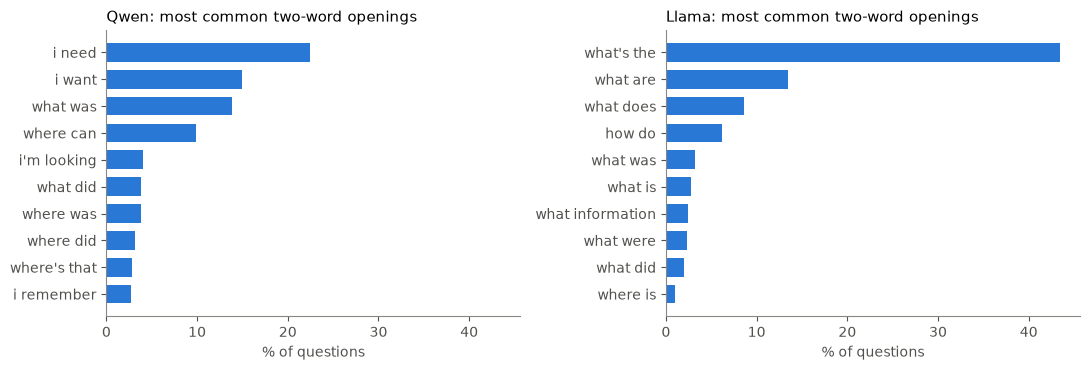


query  www.medicalmarijuanapa.gov
title  PA.gov | health.pa.gov/My%20Health/Diseases%20and%20Conditions/M-P/MedicalMarijuana/Pages/default.aspx
Qwen   I need that page about medical marijuana rules in Pennsylvania again.
Llama  What's the information on medical marijuana that I found on the Pennsylvania health website?

query  f.13 in sap
title  What is GR IR Clearing? Why is F.13 Run? | sap.ittoolbox.com/groups/technical-functional/sap-acct/what-is-gr-ir-clearing-why-is-f13-run-5133883
Qwen   What was that SAP F.13 explanation I read about clearing?
Llama  What does F.13 do in SAP accounting?

query  torrus
title  Torus | en.wikipedia.org/wiki/Torus
Qwen   What was that geometry page I read about a torus?
Llama  What is that shape called that looks like a doughnut?

query  is a living trust revocable or irrevocable
title  What is a Revocable Trust versus Irrevocable Trust | dummies.com/personal-finance/estate-planning/revocable-versus-irrevocable-trusts
Qwen   I was reading about liv

In [8]:
def copies_title(question, title):
    # True if the question repeats four or more consecutive title words.
    t = re.findall(r"\w+", title.lower())
    q = " " + " ".join(re.findall(r"\w+", question.lower())) + " "
    return any(" " + " ".join(t[i:i + 4]) + " " in q for i in range(len(t) - 3))


# Llama and Qwen questions for the same validation and test pages.
both = data[held_out]
openings = {}
for name, column in [("Qwen", "train_question"), ("Llama", "test_question")]:
    words = both[column].str.split().str.len()
    copies = np.mean([copies_title(q, t) for q, t in zip(both[column], both["title"])])
    print(f"{name:5}  mean {words.mean():4.1f} words, {words.between(6, 20).mean():5.1%} within 6-20 words, "
          f"{copies:5.1%} copy 4+ title words, {both[column].duplicated().sum()} duplicates")
    openings[name] = both[column].str.lower().str.split().str[:2].str.join(" ").value_counts().head(10) / len(both) * 100
print(f"Llama test_score: median {both['test_score'].median():.3f}, Qwen train_score: median {both['train_score'].median():.3f}")

side_by_side = pd.DataFrame({"Qwen opening": openings["Qwen"].index, "Qwen %": openings["Qwen"].values.round(1),
                             "Llama opening": openings["Llama"].index, "Llama %": openings["Llama"].values.round(1)})
print(side_by_side.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, name in zip(axes, ["Qwen", "Llama"]):
    ax.barh(openings[name].index, openings[name].values, color=BLUE, height=0.7)
    ax.invert_yaxis()
    ax.set(title=f"{name}: most common two-word openings", xlabel="% of questions")
plt.tight_layout()
plt.savefig("results/llama_vs_qwen_openings.png", dpi=200, bbox_inches="tight")
plt.show()

for row in both.sample(8, random_state=SEED).itertuples():
    print(f"\nquery  {row.query}\ntitle  {row.title} | {row.url}\nQwen   {row.train_question}\nLlama  {row.test_question}")

In [9]:
entry_text = {did: make_entry(title, url) for did, title, url in zip(data["answer_did"], data["title"], data["url"])}
all_dids = data["answer_did"].to_numpy()
did_position = {d: i for i, d in enumerate(all_dids)}

# One BM25 index over every page serves the histories, the BM25 condition and hard-negative mining.
# Its build time per entry is BM25's entry cost in the speed file.
stemmer = Stemmer.Stemmer("english")
start = time.perf_counter()
retriever = bm25s.BM25(k1=1.2, b=0.75)
retriever.index(bm25s.tokenize([entry_text[d] for d in all_dids], stopwords="en", stemmer=stemmer, show_progress=False),
                show_progress=False)
bm25_entry_ms = (time.perf_counter() - start) * 1000 / len(all_dids)
print(f"indexed {len(all_dids):,} entries, {bm25_entry_ms:.4f} ms per entry, vocabulary {len(retriever.vocab_dict):,} terms")

indexed 300,000 entries, 0.0082 ms per entry, vocabulary 254,316 terms


In [10]:
LOOKALIKES = 100
RANDOM_FILLERS = 99


def build_history(qid, answer_did, clicked):
    # Look-alikes: the pages BM25 finds most similar to the answer's own entry, skipping clicked pages.
    tokens = bm25s.tokenize([entry_text[answer_did]], stopwords="en", stemmer=stemmer, return_ids=False, show_progress=False)[0]
    scores = retriever.get_scores(tokens)
    lookalikes = []
    for i in np.argsort(-scores, kind="stable")[:LOOKALIKES + len(clicked)]:
        if all_dids[i] not in clicked and len(lookalikes) < LOOKALIKES:
            lookalikes.append(all_dids[i])
    zero_scores = sum(scores[did_position[d]] == 0 for d in lookalikes)

    rng = np.random.default_rng(seeded_hash(qid) % 2**32)
    chosen = set(lookalikes) | {answer_did}
    fillers = []
    while len(fillers) < RANDOM_FILLERS:
        d = all_dids[rng.integers(len(all_dids))]
        if d not in clicked and d not in chosen:
            fillers.append(d)
            chosen.add(d)

    history = [answer_did] + lookalikes + fillers
    history.sort(key=lambda d: seeded_hash(qid + d))
    assert len(set(history)) == 200 and sum(d in clicked for d in history) == 1
    return history, zero_scores


if os.path.exists(HISTORIES_PATH):
    histories = pd.read_parquet(HISTORIES_PATH)
else:
    held = data[held_out]
    results = [build_history(r.qid, r.answer_did, set(r.clicked_dids)) for r in tqdm(held.itertuples(), total=len(held))]
    histories = pd.DataFrame({"qid": held["qid"].values, "history_dids": [h for h, _ in results]})
    zero = np.array([z for _, z in results])
    print(f"look-alikes with no word in common with the answer: {zero.sum() / (LOOKALIKES * len(zero)):.2%}, "
          f"{(zero > 0).mean():.1%} of histories have some")
    histories.to_parquet(HISTORIES_PATH, index=False)
print(f"{len(histories):,} histories")

for row in data[held_out].merge(histories, on="qid").head(2).itertuples():
    print(f"\nquestion  {row.test_question}\nanswer    {entry_text[row.answer_did]}")
    for d in list(row.history_dids)[:8]:
        print(f"   {'*' if d == row.answer_did else ' '} {entry_text[d]}")
    print("   ...")

2,500 histories

question  What is that Straight Talk company's customer service policy called?
answer    ABOUT STRAIGHT TALK | straighttalk.com/wps/portal/home
     WHAT WOULD YOU LIKE TO DO? | straighttalk.com/wps/portal/home/Activate/byop
     Chief of Psychiatry | bcm.edu/healthcare/care-centers/psychiatry/clinics/ben-taub-harris-health-system
     War for the Planet of the Apes  ( 2017) | imdb.com/title/tt3450958
     Business | gwinnettcounty.com/portal/gwinnett/Home
     CalWORKs | dpss.lacounty.gov/wps/portal/dpss/main/programs-and-services/calworks
     Got questions? | portal.eyemedvisioncare.com/wps/portal/em/eyemed/members/faqglossary
   * ABOUT STRAIGHT TALK | straighttalk.com/wps/portal/home
     Callie Torres | greysanatomy.wikia.com/wiki/Callie_Torres
   ...

question  How do I use arrays within arrays in JavaScript?
answer    JavaScript Arrays | w3schools.com/js/js_arrays.asp
     ASP.NET Razor - Markup | w3schools.com/ASp/razor_intro.asp
     JavaScript String Referen

In [11]:
data = data.merge(splits, on="qid")

validation_rows = data[data["split"] == "validation"].merge(histories, on="qid").reset_index(drop=True)
test_rows = data[data["split"] == "test"].merge(histories, on="qid").reset_index(drop=True)
for rows in [validation_rows, test_rows]:
    rows["history_dids"] = rows["history_dids"].map(list)
    assert rows["test_question"].notna().all()
    assert all(len(h) == 200 and a in h for a, h in zip(rows["answer_did"], rows["history_dids"]))

# Tie-break key for every page that appears in a history.
did_hash = {d: seeded_hash(d) for h in pd.concat([validation_rows, test_rows])["history_dids"] for d in h}
print(data["split"].value_counts().to_string())
print(f"{len(validation_rows):,} validation and {len(test_rows):,} test histories")

split
train         297500
test            2000
validation       500
500 validation and 2,000 test histories


In [12]:
# Choices use the validation Llama questions. The Qwen questions are written like the training questions and the
# keyword queries were typed by real people, so a gain that holds on all three is not just fitting one LLM's style.
SOURCES = [("validation", "llama", "test_question"), ("validation", "qwen", "train_question"), ("validation", "keyword", "query"),
           ("test", "llama", "test_question"), ("test", "qwen", "train_question"), ("test", "keyword", "query")]
# Experiment mode (RUN_FINAL = False): one seed-0 fine-tuning run, validation questions only, and every
# result goes to results/experiments/<EXPERIMENT>/ instead of results/rankings and results/speed.
if RUN_FINAL:
    OUT_DIR = "results"
    EVAL_SOURCES = SOURCES
    RUNS = {"bge_ft_seed0": (0, None), "bge_ft_seed1": (1, None), "bge_ft_seed2": (2, None),  # run: (seed, question rows)
            "bge_ft_25k_seed0": (0, 25_000), "bge_ft_100k_seed0": (0, 100_000)}
else:
    OUT_DIR = f"results/experiments/{EXPERIMENT}"
    EVAL_SOURCES = SOURCES[:3]
    if SCREEN:
        EVAL_SOURCES = [SOURCES[0], SOURCES[2]]  # screening uses the Llama questions and keyword queries
    # A reranker experiment reuses the look-alike bi-encoder as its first stage instead of training one.
    RUNS = {"exp_lookalike-negatives" if RERANKER else f"exp_{EXPERIMENT}": (TRAIN_SEED, None)}
for folder in [f"{OUT_DIR}/rankings", f"{OUT_DIR}/speed"]:
    os.makedirs(folder, exist_ok=True)
validation_scores = {}  # validation metrics of every model ranked in this run; Llama under its name, others as <name>_<source>


def rank_by_scores(scores, history):
    # Highest score first; ties broken by the seeded hash of the page id.
    order = np.lexsort((np.array([did_hash[d] for d in history]), -scores))
    return [history[i] for i in order]


def recall_at(rankings, answers, k):
    return float(np.mean([a in r[:k] for r, a in zip(rankings, answers)]))


def mean_reciprocal_rank(rankings, answers):
    return float(np.mean([1 / (r.index(a) + 1) for r, a in zip(rankings, answers)]))


def metrics_of(rankings, answers):
    metrics = {f"recall@{k}": recall_at(rankings, answers, k) for k in [1, 5, 10, 20, 50, 100]}
    return {**metrics, "mrr": mean_reciprocal_rank(rankings, answers)}


# Off-the-shelf bge-small already passes 85% validation Recall@5, so choices use Recall@1, with MRR breaking ties.
def score_key(metrics):
    return (metrics["recall@1"], metrics["mrr"])


def evaluate(name, rank):
    # rank(questions, histories) returns the rankings. Ranks every source in EVAL_SOURCES and writes the rankings file.
    parts = []
    for split, source, column in EVAL_SOURCES:
        rows = validation_rows if split == "validation" else test_rows
        if rows[column].isna().any():
            print(f"{name} {split:10} {source:7} skipped: {rows[column].isna().sum():,} questions not written yet")
            continue
        rankings = rank(rows[column].tolist(), rows["history_dids"].tolist())
        metrics = metrics_of(rankings, rows["answer_did"])
        if split == "validation":
            validation_scores[name if source == "llama" else f"{name}_{source}"] = metrics
        print(f"{name} {split:10} {source:7} Recall@1 {metrics['recall@1']:.3f}, "
              f"Recall@5 {metrics['recall@5']:.3f}, Recall@10 {metrics['recall@10']:.3f}, "
              f"Recall@20 {metrics['recall@20']:.3f}, Recall@50 {metrics['recall@50']:.3f}, MRR {metrics['mrr']:.3f}")
        parts.append(pd.DataFrame({"qid": rows["qid"], "split": split, "source": source, "ranked_dids": rankings}))
    rankings = pd.concat(parts, ignore_index=True)
    rankings.to_parquet(f"{OUT_DIR}/rankings/{name}.parquet", index=False)
    return rankings


def show_examples(rankings):
    # Five validation questions: where the answer landed, and the top 3 entries.
    validation = rankings[(rankings["split"] == "validation") & (rankings["source"] == "llama")].merge(validation_rows[["qid", "answer_did", "test_question"]], on="qid")
    for row in validation.sample(5, random_state=SEED).itertuples():
        print(f"\nQ: {row.test_question}")
        print(f"   answer (rank {row.ranked_dids.index(row.answer_did) + 1}): {entry_text[row.answer_did]}")
        for i, did in enumerate(row.ranked_dids[:3], start=1):
            print(f"   {'*' if did == row.answer_did else ' '}{i}. {entry_text[did]}")

In [13]:
def bm25_scores(text):
    # BM25 score of every page for this text; words that appear in no entry score nothing.
    tokens = bm25s.tokenize([text], stopwords="en", stemmer=stemmer, return_ids=False, show_progress=False)[0]
    tokens = [t for t in tokens if t in retriever.vocab_dict]
    return retriever.get_scores(tokens) if tokens else np.zeros(len(all_dids))


def bm25_rank_one(question, history):
    return rank_by_scores(bm25_scores(question)[[did_position[d] for d in history]], history)


def bm25_rank(questions, histories):
    return [bm25_rank_one(q, h) for q, h in zip(tqdm(questions, desc="BM25"), histories)]


bm25_rankings = evaluate("bm25", bm25_rank)
show_examples(bm25_rankings)

BM25: 100%|██████████| 500/500 [00:00<00:00, 6055.01it/s]


bm25 validation llama   Recall@1 0.476, Recall@5 0.708, MRR 0.582


BM25: 100%|██████████| 2000/2000 [00:00<00:00, 6082.24it/s]


bm25 test       llama   Recall@1 0.486, Recall@5 0.717, MRR 0.593


BM25: 100%|██████████| 2000/2000 [00:00<00:00, 6104.54it/s]


bm25 test       qwen    Recall@1 0.477, Recall@5 0.701, MRR 0.581


BM25: 100%|██████████| 2000/2000 [00:00<00:00, 8742.49it/s]


bm25 test       keyword Recall@1 0.410, Recall@5 0.637, MRR 0.518

Q: What does the Wikipedia article about the right to assemble say about that?
   answer (rank 6): Freedom of assembly | en.wikipedia.org/wiki/Freedom_of_assembly
    1. assembly | thefreedictionary.com/assembly
    2. Symptoms of a Bad or Failing Strut Assembly | yourmechanic.com/article/symptoms-of-a-bad-or-failing-strut-assembly
    3. assembler | searchdatacenter.techtarget.com/definition/assembler

Q: What's the layout of that Mystic Seaport I was looking at?
   answer (rank 1): Mystic Seaport | mapquest.com/us/ct/mystic-seaport-283398121
   *1. Mystic Seaport | mapquest.com/us/ct/mystic-seaport-283398121
    2. Mystic Seaport | tripadvisor.com/Attraction_Review-g33845-d104984-Reviews-Mystic_Seaport-Mystic_Connecticut.html
    3. mystical | thesaurus.com/browse/mystical

Q: What's the name of that horse breed I read about on Wikipedia?
   answer (rank 91): Lipizzan | en.wikipedia.org/wiki/Lipizzan
    1. Principles

In [14]:
# CPU time per question: tokenize, score the 200 history entries, sort. The entry cost is the index build time.
question_times = []
for question, history in zip(test_rows["test_question"], test_rows["history_dids"]):
    start = time.perf_counter()
    bm25_rank_one(question, history)
    question_times.append((time.perf_counter() - start) * 1000)

speed = {"entry_ms": bm25_entry_ms, "question_ms": float(np.mean(question_times))}
with open(f"{OUT_DIR}/speed/bm25.json", "w") as f:
    json.dump(speed, f, indent=2)
print(f"{len(question_times):,} test questions: mean {speed['question_ms']:.2f} ms, median {np.median(question_times):.2f} ms per question")

2,000 test questions: mean 0.15 ms, median 0.15 ms per question


In [15]:
BASE_PROMPTS = {path: prompts for path, prompts in FIRST_STAGE_CANDIDATES.values()}


def load_model(path, device):
    # A base model gets its screening prompts (bge-small, not screened, the bge prefix); a trained model keeps its saved prompts.
    prompts = None if path.startswith("models/") else BASE_PROMPTS.get(path, {"query": QUERY_PREFIX})
    # Full-precision weights: mxbai's config loads float16, whose weights the optimizer turns into NaN.
    model = SentenceTransformer(path, device=device, prompts=prompts, model_kwargs={"dtype": torch.float32})
    model.max_seq_length = MAX_LENGTH
    return model


base_model = load_model(BASE_MODEL, DEVICE)
QUERY_PROMPT = base_model.prompts["query"]
PASSAGE_PROMPT = base_model.prompts.get("passage") or base_model.prompts.get("document") or ""  # e5: "passage: "
print(f"{BASE_MODEL} on {DEVICE}, max length {base_model.max_seq_length}, query prompt {QUERY_PROMPT!r}, "
      f"passage prompt {PASSAGE_PROMPT!r}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 30210.89it/s]


BAAI/bge-small-en-v1.5 on mps, max length 64


230,804 distinct entries across 2,500 histories


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (71 > 64). Running this sequence through the model will result in indexing errors


entries over 64 tokens:   0.74%
questions over 64 tokens: 0.00%


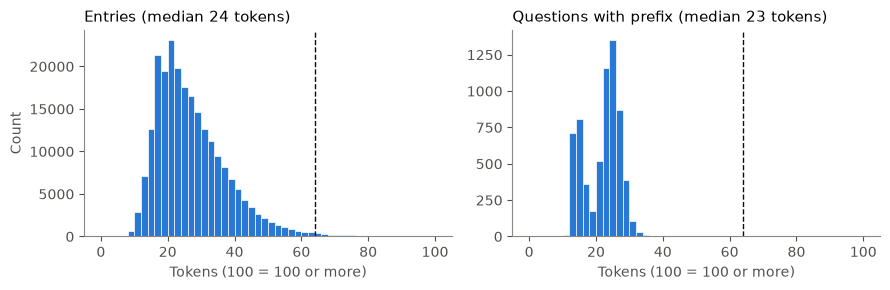

In [16]:
eval_dids = sorted(set(d for h in histories["history_dids"] for d in h))
print(f"{len(eval_dids):,} distinct entries across {len(histories):,} histories")

# How often the 64-token limit cuts text off, for entries and for prefixed questions.
questions = pd.concat([validation_rows["test_question"], test_rows["test_question"], test_rows["train_question"], test_rows["query"]])
entry_tokens = pd.Series([len(t) for t in base_model.tokenizer([entry_text[d] for d in eval_dids])["input_ids"]])
question_tokens = pd.Series([len(t) for t in base_model.tokenizer([QUERY_PROMPT + q for q in questions])["input_ids"]])
print(f"entries over {MAX_LENGTH} tokens:   {(entry_tokens > MAX_LENGTH).mean():.2%}")
print(f"questions over {MAX_LENGTH} tokens: {(question_tokens > MAX_LENGTH).mean():.2%}")

if URL_WORDS:
    # The same entries in the plain "title | url" format, for comparison.
    pages = data.set_index("answer_did").loc[eval_dids]
    plain = [f"{t} | {u}" for t, u in zip(pages["title"], pages["url"])]
    plain_tokens = pd.Series([len(t) for t in base_model.tokenizer(plain)["input_ids"]])
    print(f"entries over {MAX_LENGTH} tokens with the plain url: {(plain_tokens > MAX_LENGTH).mean():.2%}")
    for i in range(0, len(eval_dids), len(eval_dids) // 6)[:6]:
        print(f"\n   {plain[i]}\n-> {entry_text[eval_dids[i]]}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, tokens, name in [(axes[0], entry_tokens, "Entries"), (axes[1], question_tokens, "Questions with prefix")]:
    ax.hist(tokens.clip(upper=100), bins=range(0, 102, 2), color=BLUE, edgecolor="white", linewidth=0.5)
    ax.axvline(MAX_LENGTH, color="#0b0b0b", linestyle="--", linewidth=1)
    ax.set(title=f"{name} (median {tokens.median():.0f} tokens)", xlabel="Tokens (100 = 100 or more)")
axes[0].set_ylabel("Count")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/{BASE_NAME}_token_lengths.png", dpi=200, bbox_inches="tight")
plt.show()

In [17]:
def encode_entries(model, dids):
    vectors = model.encode([entry_text[d] for d in dids], prompt=PASSAGE_PROMPT, batch_size=256, normalize_embeddings=True,
                           convert_to_numpy=True, show_progress_bar=True)
    return dict(zip(dids, vectors))


def dense_ranker(model):
    # rank(questions, histories) for this model; each entry is encoded once and reused across sources.
    entry_vectors = {}

    def rank(questions, histories):
        missing = sorted(set(d for h in histories for d in h) - entry_vectors.keys())
        if missing:
            entry_vectors.update(encode_entries(model, missing))
        question_vectors = model.encode(list(questions), prompt_name="query", batch_size=256,
                                        normalize_embeddings=True, convert_to_numpy=True)
        return [rank_by_scores(np.array([entry_vectors[d] for d in h]) @ v, h) for v, h in zip(question_vectors, histories)]
    return rank


base_rankings = evaluate(BASE_NAME, dense_ranker(base_model))
show_examples(base_rankings)

Batches: 100%|██████████| 316/316 [00:30<00:00, 10.41it/s]


bge_base validation llama   Recall@1 0.654, Recall@5 0.896, MRR 0.764


Batches: 100%|██████████| 587/587 [00:54<00:00, 10.69it/s]


bge_base test       llama   Recall@1 0.676, Recall@5 0.896, MRR 0.773
bge_base test       qwen    Recall@1 0.643, Recall@5 0.874, MRR 0.746
bge_base test       keyword Recall@1 0.591, Recall@5 0.842, MRR 0.702

Q: What does the Wikipedia article about the right to assemble say about that?
   answer (rank 1): Freedom of assembly | en.wikipedia.org/wiki/Freedom_of_assembly
   *1. Freedom of assembly | en.wikipedia.org/wiki/Freedom_of_assembly
    2. Vehicle Assembly Building | en.wikipedia.org/wiki/Vehicle_Assembly_Building
    3. assembly | thefreedictionary.com/assembly

Q: What's the layout of that Mystic Seaport I was looking at?
   answer (rank 1): Mystic Seaport | mapquest.com/us/ct/mystic-seaport-283398121
   *1. Mystic Seaport | mapquest.com/us/ct/mystic-seaport-283398121
    2. Mystic Seaport | tripadvisor.com/Attraction_Review-g33845-d104984-Reviews-Mystic_Seaport-Mystic_Connecticut.html
    3. Into the Mystic | en.wikipedia.org/wiki/Into_the_Mystic

Q: What's the name of that 

In [18]:
def dense_speed(name, path):
    # CPU time on a second copy of the model: the entries of 50 test histories, then 500 test questions.
    model = load_model(path, "cpu")
    rows = test_rows.head(500)
    model.encode(["warm up"], prompt_name="query")

    entries = [entry_text[d] for h in rows["history_dids"].head(50) for d in h]
    start = time.perf_counter()
    entry_vectors = model.encode(entries, prompt=PASSAGE_PROMPT, batch_size=256, normalize_embeddings=True, convert_to_numpy=True)
    entry_ms = (time.perf_counter() - start) * 1000 / len(entries)

    # Scoring cost does not depend on which 200 entries, so the 500 questions reuse the 50 encoded histories.
    histories_vectors = entry_vectors.reshape(50, 200, -1)
    start = time.perf_counter()
    for i, question in enumerate(tqdm(rows["test_question"], desc=f"{name} CPU timing")):
        question_vector = model.encode(question, prompt_name="query", normalize_embeddings=True, convert_to_numpy=True)
        np.argsort(-(histories_vectors[i % 50] @ question_vector))
    question_ms = (time.perf_counter() - start) * 1000 / len(rows)

    with open(f"{OUT_DIR}/speed/{name}.json", "w") as f:
        json.dump({"entry_ms": entry_ms, "question_ms": question_ms}, f, indent=2)
    print(f"{name}: {entry_ms:.2f} ms per entry, {question_ms:.2f} ms per question on CPU ({torch.get_num_threads()} threads)")


dense_speed(BASE_NAME, BASE_MODEL)

bge_base CPU timing: 100%|██████████| 500/500 [00:02<00:00, 176.46it/s]

bge_base: 1.72 ms per entry, 5.67 ms per question on CPU (6 threads)


In [ ]:
# Screening (SCREEN = True): first-stage candidates off the shelf on the validation Llama questions and keyword queries.
SCREEN_SOURCES = [("llama", "test_question"), ("keyword", "query")]
SCREEN_KS = [1, 5, 10, 20, 50, 100]
SCREEN_MAX_LENGTH = 128
screening = {"first_stage": {}, "reranker": {}}
screen_rankings = {}  # (model, source) -> validation rankings, for the reranker screening


def free_memory():
    gc.collect()
    if DEVICE == "mps":
        torch.mps.empty_cache()


def first_stage_metrics(rankings, answers):
    metrics = {f"recall@{k}": recall_at(rankings, answers, k) for k in SCREEN_KS}
    return {**metrics, "mrr": mean_reciprocal_rank(rankings, answers)}


def screen_first_stage(name, rank_one, entry_ms):
    # rank_one(question, history) ranks one history; the time per question is measured on the Llama questions.
    screening["first_stage"][name] = {"entry_ms": entry_ms}
    for source, column in SCREEN_SOURCES:
        rankings, times = [], []
        for question, history in zip(validation_rows[column], validation_rows["history_dids"]):
            start = time.perf_counter()
            rankings.append(rank_one(question, history))
            times.append((time.perf_counter() - start) * 1000)
        screen_rankings[(name, source)] = rankings
        screening["first_stage"][name][source] = first_stage_metrics(rankings, validation_rows["answer_did"])
        if source == "llama":
            screening["first_stage"][name]["question_ms"] = float(np.mean(times))
        print(f"{name:30} {source:7} " + ", ".join(f"{m} {v:.3f}" for m, v in screening["first_stage"][name][source].items()))


if SCREEN:
    screen_dids = sorted(set(d for h in validation_rows["history_dids"] for d in h))
    print(f"{len(screen_dids):,} distinct validation entries")
    screen_first_stage("bm25", bm25_rank_one, bm25_entry_ms)  # BM25 runs on the CPU

    for name, (path, prompts) in FIRST_STAGE_CANDIDATES.items():
        model = SentenceTransformer(path, device=DEVICE, prompts=prompts)
        model.max_seq_length = SCREEN_MAX_LENGTH
        query_prompt = "query" if "query" in model.prompts else None
        passage_prompt = next((p for p in ["passage", "document"] if p in model.prompts), None)
        print(f"\n{name}: prompts {model.prompts}, query prompt {query_prompt}, passage prompt {passage_prompt}")
        model.encode(["warm up"] * 8, prompt_name=passage_prompt)

        # GPU time per entry: every validation entry encoded in batches.
        start = time.perf_counter()
        vectors = model.encode([entry_text[d] for d in screen_dids], prompt_name=passage_prompt, batch_size=64,
                               normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=True)
        entry_ms = (time.perf_counter() - start) * 1000 / len(screen_dids)
        vector_of = dict(zip(screen_dids, vectors))

        # GPU time per question: encode one question, score its 200 entries, sort.
        def rank_one(question, history):
            v = model.encode(question, prompt_name=query_prompt, normalize_embeddings=True, convert_to_numpy=True)
            return rank_by_scores(np.array([vector_of[d] for d in history]) @ v, history)

        screen_first_stage(name, rank_one, entry_ms)
        print(f"{name}: {entry_ms:.2f} ms per entry, {screening['first_stage'][name]['question_ms']:.1f} ms per question")
        del model, vectors, vector_of
        free_memory()


In [ ]:
# Screening: each reranker reorders the top k of one fixed first stage, the off-the-shelf bi-encoder with the best
# Llama Recall@50 (Recall@10 breaks ties). The reranker score alone decides the order; there is no fusion.
SCREEN_RERANK_KS = [10, 20, 50]
RERANK_INSTRUCTION = "Given a question about a web page the user visited, judge whether this browser history entry (title | url) is that page"
RERANKER_CANDIDATES = ["cross-encoder/ms-marco-MiniLM-L6-v2", "BAAI/bge-reranker-base", "Alibaba-NLP/gte-reranker-modernbert-base",
                       "BAAI/bge-reranker-v2-m3", "Qwen/Qwen3-Reranker-0.6B"]


def screen_reranker(path):
    if path.startswith("Qwen/"):
        # An LLM reranker reads the instruction inside its chat template, which takes about 85 more tokens.
        return CrossEncoder(path, max_length=128 + 96, device=DEVICE, prompts={"query": RERANK_INSTRUCTION},
                            default_prompt_name="query", model_kwargs={"dtype": torch.bfloat16})
    return CrossEncoder(path, max_length=128, device=DEVICE)


# One question at a time, its k pairs in one batch; the pages below the top k keep their first-stage order.
def screen_rerank(model, first_rankings, questions, k):
    rankings, times = [], []
    for ranking, question in zip(first_rankings, questions):
        top = ranking[:k]
        start = time.perf_counter()
        scores = model.predict([(question, entry_text[d]) for d in top], batch_size=k)
        times.append((time.perf_counter() - start) * 1000)
        rankings.append(rank_by_scores(np.asarray(scores, dtype=float), top) + ranking[k:])
    return rankings, float(np.mean(times))


if SCREEN:
    bi_encoders = [n for n in screening["first_stage"] if n != "bm25"]
    first_stage = max(bi_encoders, key=lambda n: (screening["first_stage"][n]["llama"]["recall@50"],
                                                  screening["first_stage"][n]["llama"]["recall@10"]))
    screening["reranker_first_stage"] = first_stage
    print(f"first stage: {first_stage}, Llama " + ", ".join(
        f"Recall@{k} {screening['first_stage'][first_stage]['llama'][f'recall@{k}']:.3f}" for k in SCREEN_RERANK_KS))

    for path in RERANKER_CANDIDATES:
        model = screen_reranker(path)
        name = path.split("/")[1]
        screening["reranker"][name] = {}
        for k in SCREEN_RERANK_KS:
            model.predict([("warm up", "warm up")] * k, batch_size=k)
            for source, column in SCREEN_SOURCES:
                rankings, ms = screen_rerank(model, screen_rankings[(first_stage, source)], validation_rows[column], k)
                metrics = {**metrics_of(rankings, validation_rows["answer_did"]), "ms_per_question": ms}
                screening["reranker"][name][f"k{k}_{source}"] = metrics
                print(f"{name:30} k={k:2} {source:7} Recall@1 {metrics['recall@1']:.3f}, Recall@5 {metrics['recall@5']:.3f}, "
                      f"MRR {metrics['mrr']:.3f}, {ms:.1f} ms per question")
        del model
        free_memory()


In [ ]:
# Screening results: validation.json, two tables and the Recall@k chart.
if SCREEN:
    with open(f"{OUT_DIR}/validation.json", "w") as f:
        json.dump({"settings": {**SETTINGS, "SCREEN_MAX_LENGTH": SCREEN_MAX_LENGTH, "RERANK_INSTRUCTION": RERANK_INSTRUCTION,
                                "validation_questions": len(validation_rows), "device": DEVICE}, "screening": screening}, f, indent=2)

    lines = [f"# Off-the-shelf screening ({len(validation_rows)} validation questions, {DEVICE})", "",
             "## First stage", "",
             "Llama questions; keyword Recall@50 in the last column. BM25 times are on the CPU, the others on the GPU.", "",
             "| Model | R@1 | R@5 | R@10 | R@20 | R@50 | R@100 | MRR | ms/entry | ms/question | Keyword R@50 |",
             "|---|---|---|---|---|---|---|---|---|---|---|"]
    for name, r in screening["first_stage"].items():
        llama = r["llama"]
        lines.append(f"| {name} | " + " | ".join(f"{llama[f'recall@{k}']:.3f}" for k in SCREEN_KS)
                     + f" | {llama['mrr']:.3f} | {r['entry_ms']:.3f} | {r['question_ms']:.1f} | {r['keyword']['recall@50']:.3f} |")
    lines += ["", f"## Rerankers on the top k of {screening['reranker_first_stage']}", "",
              "Llama questions, reranker score alone; keyword Recall@1 in the last column. GPU time per question, k pairs in one batch.", "",
              "| Reranker | k | R@1 | R@5 | MRR | ms/question | Keyword R@1 |", "|---|---|---|---|---|---|---|"]
    for name, r in screening["reranker"].items():
        for k in SCREEN_RERANK_KS:
            llama = r[f"k{k}_llama"]
            lines.append(f"| {name} | {k} | {llama['recall@1']:.3f} | {llama['recall@5']:.3f} | {llama['mrr']:.3f} | "
                         f"{llama['ms_per_question']:.0f} | {r[f'k{k}_keyword']['recall@1']:.3f} |")
    with open(f"{OUT_DIR}/screening.md", "w") as f:
        f.write("\n".join(lines) + "\n")
    print("\n".join(lines))

    fig, ax = plt.subplots(figsize=(7, 4))
    for name, r in screening["first_stage"].items():
        ax.plot(SCREEN_KS, [r["llama"][f"recall@{k}"] for k in SCREEN_KS], marker="o", markersize=3, label=name)
    ax.set_xscale("log")
    ax.set_xticks(SCREEN_KS, [str(k) for k in SCREEN_KS])
    ax.set_xlabel("k")
    ax.set_ylabel("Recall@k")
    ax.set_title("First stage off the shelf, validation Llama questions")
    ax.legend(fontsize=8, frameon=False)
    fig.tight_layout()
    fig.savefig(f"{OUT_DIR}/first_stage_recall_at_k.png", dpi=150)
    plt.show()


In [19]:
held_out_clicks = set(d for clicks in pd.concat([validation_rows, test_rows])["clicked_dids"] for d in clicks)
train = data[data["split"] == "train"].reset_index(drop=True)
leaks = train["answer_did"].isin(held_out_clicks)
print(f"{len(train):,} train rows, {leaks.sum():,} dropped because their page was clicked for a validation or test query")
train = train[~leaks]

# Hard negatives may come from any leak-free training page, rewritten or not.
train_entry_dids = sorted(train["answer_did"])
missing = train["train_question"].isna()
print(f"{missing.sum():,} rows without a Qwen rewrite are dropped")
train = train[~missing].reset_index(drop=True)
filter_log = {"train_rows": int((data["split"] == "train").sum()), "leak_dropped": int(leaks.sum()),
              "no_rewrite_dropped": int(missing.sum())}
print(f"{len(train):,} training rows")

297,500 train rows, 1,051 dropped because their page was clicked for a validation or test query
0 rows without a Qwen rewrite are dropped
296,449 training rows


In [20]:
title_copy = pd.Series([copies_title(q, t) for q, t in zip(train["train_question"], train["title"])], index=train.index)
print(f"copy 4+ title words: {title_copy.sum():,} rows ({title_copy.mean():.1%})")
for row in train[title_copy].sample(min(5, title_copy.sum()), random_state=SEED).itertuples():
    print(f"   {row.title[:70]!r:75} -> {row.train_question}")
# Reported only: the shared prompt allows title words, so these rows stay.
filter_log["title_copies"] = 0

copy 4+ title words: 14,569 rows (4.9%)
   "What's new at Carpenter's Paint and Hardware?"                             -> Where was that Carpenter's Paint and Hardware page I saw?
   '10 Interesting Facts About Ulysses S. Grant'                               -> I remember reading some fun facts about Ulysses S. Grant—where was that page?
   'The Four Noble Truths'                                                     -> I need that page about the four noble truths again.
   'Words ending in It'                                                        -> I'm looking for that list of words ending in "it" I found earlier.
   'California Food Handler Card'                                              -> Where can I find that California food handler card test I was looking at?


In [21]:
has_cjk = train["train_question"].str.contains("[぀-ヿ㐀-鿿가-힯]")
print(f"contain CJK characters: {has_cjk.sum():,} rows ({has_cjk.mean():.2%})")
for question in train.loc[has_cjk, "train_question"].head(5):
    print("   ", question)
train = train[~has_cjk]
filter_log["cjk"] = int(has_cjk.sum())

contain CJK characters: 3 rows (0.00%)
    What was that article I read about people破坏 property?
    What was that word for messy or混乱 I looked up earlier?
    Where was that ferry terminal I found for Oui斯特reham?


In [22]:
# The same question pointing at two pages is ambiguous, so every copy is dropped, not just the extras.
question_key = train["train_question"].str.lower().str.strip()
duplicate = question_key.duplicated(keep=False)
print(f"duplicate questions: {duplicate.sum():,} rows ({duplicate.mean():.2%}), {question_key[duplicate].nunique():,} distinct questions")
print(question_key[duplicate].value_counts().head(10).to_string())
train = train[~duplicate].reset_index(drop=True)
filter_log["duplicates"] = int(duplicate.sum())
print(f"\n{len(train):,} training rows after title, CJK and duplicate filters")

duplicate questions: 1,871 rows (0.66%), 788 distinct questions
train_question
what did that word mean i looked up earlier?                           33
i want to see that page about the town in texas i looked up.           23
i want to see that page about the town in illinois i looked up.         9
i want to see that page about the town in pennsylvania i looked up.     9
i want to see that page about the town in new york i looked up.         9
i want to see that page about the town in minnesota i looked up.        9
what was that article i read about the town in pennsylvania?            9
what was that word definition i looked up earlier?                      8
what was that article i read about the town in new york?                8
where can i find that actor's bio i saw on imdb?                        8

280,006 training rows after title, CJK and duplicate filters


opening cap removes 59,623 rows (21.3%)
                 before %  after %
train_question                    
i need that          18.2     10.0
i need to             4.2      5.4
i want to            13.6     10.0
i'm looking for       4.0      5.1
what did that         3.6      4.6
what was that        11.4     10.0
what was the          3.0      3.8
where can i           9.6     10.0
where did i           2.8      3.5
where was that        3.7      4.7


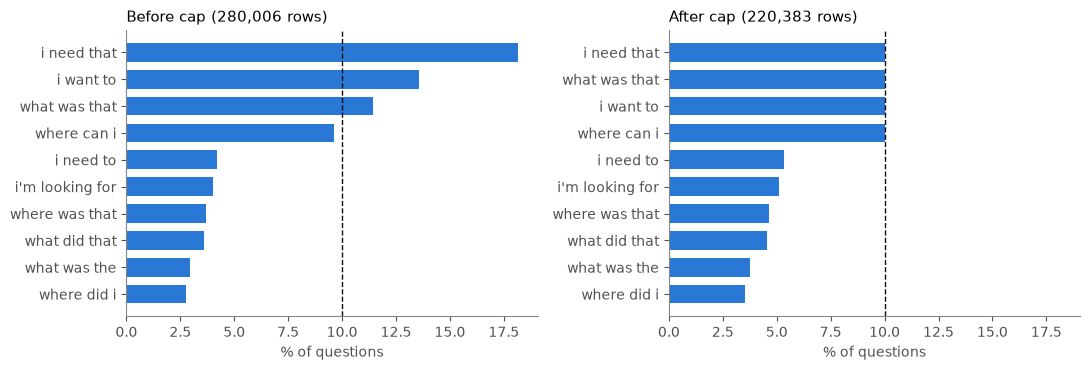

In [23]:
def opening(questions):
    return questions.str.lower().str.split().str[:3].str.join(" ")


def cap_openings(rows):
    # Trim each opening above the cap to its first rows in sample order.
    # Trimming shrinks the total, which lowers the cap, so repeat until nothing is above it.
    while True:
        openings = opening(rows["train_question"])
        cap = int(OPENING_CAP * len(rows))
        if openings.value_counts().iloc[0] <= cap:
            return rows
        rows = rows[openings.groupby(openings).cumcount() < cap]


capped = cap_openings(train)
before = opening(train["train_question"]).value_counts().head(10) / len(train) * 100
after = opening(capped["train_question"]).value_counts().head(10) / len(capped) * 100
print(f"opening cap removes {len(train) - len(capped):,} rows ({1 - len(capped) / len(train):.1%})")
print(pd.DataFrame({"before %": before.round(1), "after %": after.round(1)}).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, top, label in [(axes[0], before, f"Before cap ({len(train):,} rows)"), (axes[1], after, f"After cap ({len(capped):,} rows)")]:
    ax.barh(top.index, top.values, color=BLUE, height=0.7)
    ax.invert_yaxis()
    ax.axvline(OPENING_CAP * 100, color="#0b0b0b", linestyle="--", linewidth=1)
    ax.set(title=label, xlabel="% of questions")
plt.tight_layout()
plt.savefig("results/ft_openings.png", dpi=200, bbox_inches="tight")
plt.show()
filter_log["opening_cap_no_cutoff"] = len(train) - len(capped)

train_score quantiles:
0.05   -0.307
0.10   -0.272
0.20   -0.232
0.30   -0.208


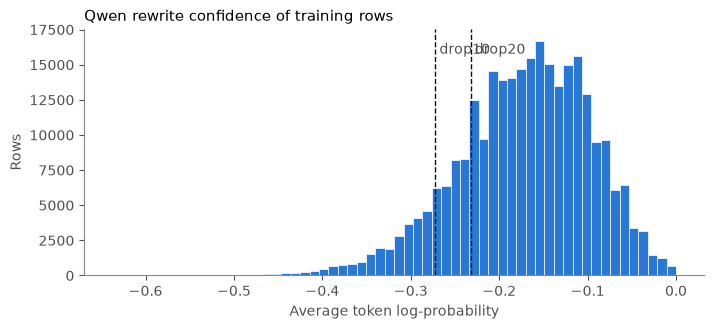

Lowest-scoring rewrites:
   -0.637  'citigrou'                          -> Where was that Citigroup page I read about?
   -0.625  'girlfriends day'                   -> What’s that holiday I found for girlfriends?
   -0.625  'horizontal sliding window air conditioner' -> I need that page about the best window AC unit again.
   -0.615  'www.agoogleaday.com'               -> Where was that fun quiz I played about googling things?
   -0.615  'eagle county classifieds'          -> That Eagle County weather page I saw, where was it?
   -0.600  'first ronald mcdonald'             -> Where was that first Ronald McDonald video I saw?
   -0.598  'the mechanic 2'                    -> Where's that video I watched with the mechanic guy and the sequel?
   -0.588  'aniversary'                        -> I was looking for that word definition on anniversary.


In [24]:
quantiles = train["train_score"].quantile([0.05, 0.10, 0.20, 0.30])
print("train_score quantiles:\n" + quantiles.round(3).to_string())
SCORE_CUTOFFS = {"none": None, "drop10": float(quantiles[0.10]), "drop20": float(quantiles[0.20])}

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(train["train_score"], bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
for name in ["drop10", "drop20"]:
    ax.axvline(SCORE_CUTOFFS[name], color="#0b0b0b", linestyle="--", linewidth=1)
    ax.text(SCORE_CUTOFFS[name], ax.get_ylim()[1] * 0.9, f" {name}", color="#52514e")
ax.set(title="Qwen rewrite confidence of training rows", xlabel="Average token log-probability", ylabel="Rows")
plt.savefig("results/ft_train_score.png", dpi=200, bbox_inches="tight")
plt.show()

print("Lowest-scoring rewrites:")
for row in train.nsmallest(8, "train_score").itertuples():
    print(f"   {row.train_score:6.3f}  {row.query!r:35} -> {row.train_question}")

In [25]:
# About 30% extra examples use the original keyword query as the question, chosen per row by seeded hash.
train["keyword"] = [seeded_hash(f"keyword:{qid}") % 100 < KEYWORD_SHARE * 100 for qid in train["qid"]]
print(f"{train['keyword'].mean():.1%} of rows also give a keyword example, e.g.")
for row in train[train["keyword"]].head(5).itertuples():
    print(f"   {row.query!r:35} | {row.train_question}")


def training_rows(cutoff_name):
    rows = train
    if SCORE_CUTOFFS[cutoff_name] is not None:
        rows = rows[rows["train_score"] >= SCORE_CUTOFFS[cutoff_name]]
    return cap_openings(rows).reset_index(drop=True).head(TRAIN_ROWS)  # TRAIN_ROWS = None keeps every row


def filters_for(cutoff_name):
    return {**filter_log, "score_cutoff": cutoff_name, "score_cutoff_value": SCORE_CUTOFFS[cutoff_name],
            "opening_cap": OPENING_CAP, "keyword_share": KEYWORD_SHARE}


for name in SCORE_CUTOFFS:
    rows = training_rows(name)
    print(f"cutoff {name:7} {len(rows):,} question rows + {rows['keyword'].sum():,} keyword rows")

30.0% of rows also give a keyword example, e.g.
   'las vegas weather network'         | Where was that Las Vegas weather forecast I saw on the Weather Network?
   'what time zone is brazil in'       | I need that page about time zones in Brazil again.
   'best african american books'       | I'm looking for that list of great African American books I saw earlier.
   '1 usd = euro'                      | I need that live exchange rate chart for euros to dollars again.
   'dragon girl names'                 | What were those dragon-themed girl names I saw earlier?
cutoff none    220,383 question rows + 66,154 keyword rows
cutoff drop10  196,012 question rows + 58,896 keyword rows
cutoff drop20  173,131 question rows + 52,025 keyword rows


In [26]:
# Reuses the global BM25 index built for the histories. Added to the BM25 scores: -inf on every page that is not a training entry, so it is never picked.
not_training = np.where(data["answer_did"].isin(train_entry_dids), 0.0, -np.inf)

In [27]:
# A page that BM25 ranks first for thousands of questions (often a title phrased as a question) is not a useful
# hard negative, and NO_DUPLICATES would need one batch per use. So each page may be a negative at most 10 times.
MAX_NEGATIVE_USES = 10
# "question": BM25 hits for the question (and keyword) text. "lookalike": BM25 hits for the positive page's own entry,
# mined the same way as the validation and test histories.
assert NEGATIVES in ["question", "lookalike"]
# The cache is named by the negatives settings and the entry format, so changing either mines again.
entry_format = seeded_hash("\n".join(entry_text[d] for d in all_dids[:1000])) % 10**6
if NEGATIVES == "question":
    NEGATIVES_PATH = f"models/checkpoints/hard_negatives_{NEGATIVES}{N_NEGATIVES}_{entry_format}.parquet"
else:
    NEGATIVES_PATH = f"models/checkpoints/lookalike_negatives_{N_NEGATIVES}_{entry_format}.parquet"


def bm25_candidates(text, clicked):
    # The 50 best-scoring training pages for this text, best first, skipping clicked pages and pages with score 0.
    scores = bm25_scores(text) + not_training
    scores[[did_position[d] for d in clicked if d in did_position]] = -np.inf
    top = np.argpartition(-scores, 50)[:50]
    top = top[np.argsort(-scores[top], kind="stable")]
    return [all_dids[i] for i in top if scores[i] > 0]


MINE_K = 60  # 50 candidates plus room for clicked pages that get skipped
training_mask = np.isfinite(not_training).astype(np.float32)


def mine_candidates(texts, clicked_lists):
    # bm25_candidates for many texts at once: one BM25 call scores them on all CPU cores.
    # A text whose top MINE_K loses too many clicked pages is scored again on its own.
    tokens = bm25s.tokenize(list(texts), stopwords="en", stemmer=stemmer, return_ids=False, show_progress=False)
    tokens = [[t for t in q if t in retriever.vocab_dict] for q in tokens]
    results = [[] for _ in tokens]  # a text with no known word has no candidates
    with_words = [i for i, q in enumerate(tokens) if q]
    docs, scores = retriever.retrieve([tokens[i] for i in with_words], k=MINE_K, n_threads=-1,
                                      weight_mask=training_mask, show_progress=False)
    for j, i in enumerate(with_words):
        clicked = set(clicked_lists[i])
        candidates = [all_dids[d] for d, s in zip(docs[j], scores[j]) if s > 0 and all_dids[d] not in clicked][:50]
        if len(candidates) < 50 and scores[j][-1] > 0:
            candidates = bm25_candidates(texts[i], clicked)
        results[i] = candidates
    return results


def random_negative(excluded, key):
    # No usable BM25 match: a random training page that was not clicked.
    k = seeded_hash(key)
    while train_entry_dids[k % len(train_entry_dids)] in excluded:
        k += 1
    return train_entry_dids[k % len(train_entry_dids)]


# Only rows that some training run will use need negatives.
used_cutoffs = list(SCORE_CUTOFFS) if SCORE_CUTOFF is None else [SCORE_CUTOFF]
used = train[train["qid"].isin(pd.concat([training_rows(name)["qid"] for name in used_cutoffs]))]
if NEGATIVES == "question":
    needed = pd.concat([
        pd.DataFrame({"qid": used["qid"], "kind": "question", "text": used["train_question"], "clicked_dids": used["clicked_dids"]}),
        pd.DataFrame({"qid": used["qid"], "kind": "keyword", "text": used["query"], "clicked_dids": used["clicked_dids"]})[used["keyword"]],
    ]).reset_index(drop=True)
else:
    # The question and keyword examples of a row share the positive page, so one mining per row serves both.
    needed = pd.DataFrame({"qid": used["qid"], "kind": "lookalike", "text": [entry_text[d] for d in used["answer_did"]],
                           "clicked_dids": used["clicked_dids"]})

if os.path.exists(NEGATIVES_PATH):
    mined = pd.read_parquet(NEGATIVES_PATH)
else:
    mined = pd.DataFrame({"qid": pd.Series(dtype=str), "kind": pd.Series(dtype=str),
                          "negative_dids": pd.Series(dtype=object), "bm25_ranks": pd.Series(dtype=object)})
todo = needed[~(needed["qid"] + ":" + needed["kind"]).isin(mined["qid"] + ":" + mined["kind"])]
print(f"{len(needed):,} examples need {N_NEGATIVES} hard negative(s), {len(todo):,} not mined yet")

uses = mined["negative_dids"].explode().value_counts().to_dict()
for start in tqdm(range(0, len(todo), 20_000)):
    chunk = todo.iloc[start:start + 20_000]
    negative_dids, ranks = [], []
    candidate_lists = mine_candidates(chunk["text"].tolist(), chunk["clicked_dids"].tolist())
    for r, candidates in zip(chunk.itertuples(), candidate_lists):
        clicked = set(r.clicked_dids)
        picked, picked_ranks = [], []
        for rank, candidate in enumerate(candidates):
            if len(picked) == N_NEGATIVES:
                break
            if NEGATIVES == "lookalike" and entry_text[candidate] == r.text:
                continue  # an unclicked copy of the positive's exact text is not a real negative
            if uses.get(candidate, 0) < MAX_NEGATIVE_USES:
                picked.append(candidate)
                picked_ranks.append(rank)
        while len(picked) < N_NEGATIVES:
            key = f"{r.qid}:{r.kind}" + (f":{len(picked)}" if picked else "")
            picked.append(random_negative(clicked | set(picked), key))
            picked_ranks.append(-1)  # -1 marks a random fallback
        for d in picked:
            uses[d] = uses.get(d, 0) + 1
        negative_dids.append(picked)
        ranks.append(picked_ranks)
    new = pd.DataFrame({"qid": chunk["qid"], "kind": chunk["kind"], "negative_dids": negative_dids, "bm25_ranks": ranks})
    mined = pd.concat([mined, new], ignore_index=True)
    mined.to_parquet(NEGATIVES_PATH, index=False)

negatives = {(q, k): list(d) for q, k, d in zip(mined["qid"], mined["kind"], mined["negative_dids"])}
if NEGATIVES == "lookalike":
    negatives = {(q, kind): d for (q, _), d in negatives.items() for kind in ["question", "keyword"]}
ranks = mined["bm25_ranks"].explode()
print(f"top BM25 page used:                  {(ranks == 0).mean():.1%}")
print(f"a lower BM25 page:                   {(ranks > 0).mean():.1%}")
print(f"random fallback:                     {(ranks == -1).mean():.2%}")
print(f"most reused negatives:\n{mined['negative_dids'].explode().map(entry_text).value_counts().head(5).to_string()}")

363,897 examples need 1 hard negative(s), 363,897 not mined yet


100%|██████████| 19/19 [06:10<00:00, 19.52s/it]


top BM25 page used:                  76.0%
a lower BM25 page:                   22.5%
random fallback:                     1.50%
most reused negatives:
negative_dids
What Time Does The Stock Market Open And Close? | nasdaq.com/article/what-time-does-the-stock-market-open-and-close-cm619778    20
Any Gunsmoke Actors Still Alive? | gunsmoketv.org/any-gunsmoke-actors-still-alive                                               20
2018 GS Pay Scale for Federal Employees | myfederalretirement.com/public/gs-pay-scale-opm.cfm                                   20
Where you can visit Nantucket before and after you visit Nantucket! | nantucket.net                                             20
Looking for a Flood Map? | msc.fema.gov                                                                                         20


In [28]:
for row in used.sample(6, random_state=SEED).itertuples():
    print(f"question  {row.train_question}")
    print(f"positive  {entry_text[row.answer_did]}")
    for did in negatives[(row.qid, "question")]:
        print(f"negative  {entry_text[did]}")
    print()

question  I need to find that guide on installing a GFCI breaker I read.
positive  What Is Better: a GFCI Receptacle or a GFCI Circuit Breaker? | thespruce.com/install-gfci-receptable-vs-breaker-1152797
negative  How to Reset Your GFCI Outlets and Circuit Breakers | laudanelectric.com/how-to-reset-your-gfci-outlets-and-circuit-breakers

question  Where can I find the driver for my Zebra ZM400 printer?
positive  Barcode Printer Software | zebra.com/us/en/products/software/barcode-printers.html
negative  Printers | zebra.com/us/en/products/printers.html

question  What does that California Proposition 65 warning mean again?
positive  California Proposition 65 (1986) | en.wikipedia.org/wiki/California_Proposition_65_(1986)
negative  Proposition 65 FAQs | oehha.ca.gov/proposition-65/proposition-65-faqs

question  How many people fit at that 6-foot table I saw earlier?
positive  How Many People Can Sit at an Eight Foot Table? | everafterguide.net/how-many-people-can-sit-at-6-ft-table.html
n

In [29]:
def build_examples(rows, hard_negatives):
    keyword_rows = rows[rows["keyword"]]
    columns = {
        "question": rows["train_question"].tolist() + keyword_rows["query"].tolist(),
        "positive": [entry_text[d] for d in rows["answer_did"]] + [entry_text[d] for d in keyword_rows["answer_did"]],
    }
    if hard_negatives:
        negative_lists = [negatives[(q, "question")] for q in rows["qid"]] + [negatives[(q, "keyword")] for q in keyword_rows["qid"]]
        for i in range(len(negative_lists[0])):
            columns[f"negative_{i + 1}"] = [entry_text[dids[i]] for dids in negative_lists]
    return Dataset.from_dict(columns)

In [30]:
class EpochValidation(TrainerCallback):
    # Validation metrics after every epoch, so one multi-epoch run shows epochs 1, 2, 3.
    def __init__(self, model, run):
        self.model, self.run, self.scores = model, run, {}

    def on_epoch_end(self, args, state, control, **kwargs):
        epoch = round(state.epoch)
        rankings = dense_ranker(self.model)(validation_rows["test_question"], validation_rows["history_dids"])
        self.scores[f"{self.run}_epoch{epoch}"] = metrics_of(rankings, validation_rows["answer_did"])
        print(f"{self.run} epoch {epoch}: validation Recall@1 {self.scores[f'{self.run}_epoch{epoch}']['recall@1']:.3f}")


def train_model(rows, run, seed, hard_negatives, filters):
    final_dir = f"models/trained/{run}"
    if os.path.exists(final_dir):
        with open(f"{final_dir}/training_info.json") as f:
            metrics = json.load(f)["validation"]
        print(f"{run}: already trained, validation Recall@1 {metrics['recall@1']:.3f}, Recall@5 {metrics['recall@5']:.3f}")
        return metrics

    checkpoint_dir = f"models/checkpoints/{run}"
    dataset = build_examples(rows, hard_negatives)
    model = load_model(BASE_MODEL, DEVICE)
    args = SentenceTransformerTrainingArguments(
        output_dir=checkpoint_dir, num_train_epochs=EPOCHS, per_device_train_batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE, warmup_ratio=WARMUP_RATIO, seed=seed,
        batch_sampler=BatchSamplers.NO_DUPLICATES,  # a page never appears twice in one batch
        prompts={"question": QUERY_PROMPT, **{c: PASSAGE_PROMPT for c in dataset.column_names[1:] if PASSAGE_PROMPT}},
        bf16=HALF_PRECISION,  # experiments only; final models train in full precision
        save_strategy="steps", save_steps=SAVE_STEPS, save_total_limit=2, logging_steps=50, report_to="none",
    )
    # The cached loss computes the same loss in mini-batches, so a larger batch fits in memory.
    if CACHED_LOSS:
        # The cached loss first embeds without gradients, where MPS attention cannot apply dropout, so use eager attention.
        model[0].auto_model.set_attn_implementation("eager")
        loss = losses.CachedMultipleNegativesRankingLoss(model, mini_batch_size=MINI_BATCH_SIZE)
    else:
        loss = losses.MultipleNegativesRankingLoss(model)
    epoch_validation = EpochValidation(model, run)
    trainer = SentenceTransformerTrainer(model=model, args=args, train_dataset=dataset, loss=loss,
                                         callbacks=[epoch_validation] if EPOCHS > 1 else [])
    last_checkpoint = get_last_checkpoint(checkpoint_dir) if os.path.isdir(checkpoint_dir) else None
    print(f"{run}: {len(dataset):,} examples, resuming from {last_checkpoint}")
    start = time.perf_counter()
    trainer.train(resume_from_checkpoint=last_checkpoint)
    training_minutes = (time.perf_counter() - start) / 60
    validation_scores.update(epoch_validation.scores)

    rankings = dense_ranker(model)(validation_rows["test_question"], validation_rows["history_dids"])
    metrics = metrics_of(rankings, validation_rows["answer_did"])
    info = {"base_model": BASE_MODEL, "seed": seed, "question_rows": len(rows), "keyword_rows": int(rows["keyword"].sum()),
            "examples": len(dataset), "hard_negatives": hard_negatives, "batch_size": BATCH_SIZE,
            "learning_rate": LEARNING_RATE, "epochs": EPOCHS, "warmup_ratio": WARMUP_RATIO, "max_seq_length": MAX_LENGTH,
            "training_minutes": training_minutes, "epoch_validation": epoch_validation.scores,
            "filters": filters, "settings": SETTINGS, "validation": metrics}
    # Save to a temporary folder and rename, so a crash mid-save never leaves a folder that looks finished.
    model.save(final_dir + ".tmp", safe_serialization=True)
    with open(f"{final_dir}.tmp/training_info.json", "w") as f:
        json.dump(info, f, indent=2)
    os.rename(final_dir + ".tmp", final_dir)
    shutil.rmtree(checkpoint_dir)
    print(f"{run}: validation Recall@1 {metrics['recall@1']:.3f}, Recall@5 {metrics['recall@5']:.3f}, "
          f"{training_minutes:.1f} minutes of training")
    return metrics

In [ ]:
# SCORE_CUTOFF = None runs the selection: one seed-0 run per train_score cutoff, then in-batch negatives only at the
# best cutoff. A cutoff name skips it and uses hard negatives at that cutoff.
if SCORE_CUTOFF is None:
    selection = {}
    for name in SCORE_CUTOFFS:
        selection[f"{name}, hard negatives"] = train_model(training_rows(name), f"select_{name}_hard", 0, True, filters_for(name))

    best_cutoff = "none"
    for name in SCORE_CUTOFFS:
        if score_key(selection[f"{name}, hard negatives"]) > score_key(selection[f"{best_cutoff}, hard negatives"]):
            best_cutoff = name
    print(f"best train_score cutoff on validation: {best_cutoff}")

    selection[f"{best_cutoff}, in-batch only"] = train_model(training_rows(best_cutoff), f"select_{best_cutoff}_inbatch", 0, False,
                                                             filters_for(best_cutoff))
    hard = selection[f"{best_cutoff}, hard negatives"]
    in_batch = selection[f"{best_cutoff}, in-batch only"]
    USE_HARD_NEGATIVES = score_key(hard) >= score_key(in_batch)  # fall back to in-batch only if hard negatives hurt
    print(f"validation Recall@1: hard negatives {hard['recall@1']:.3f}, in-batch only {in_batch['recall@1']:.3f} "
          f"-> hard negatives: {USE_HARD_NEGATIVES}")
    selected_run = f"select_{best_cutoff}_{'hard' if USE_HARD_NEGATIVES else 'inbatch'}"  # same config as the seed-0 final run

    print(pd.DataFrame(selection).T.round(3).to_string())
    fig, ax = plt.subplots(figsize=(8, 3))
    names = list(selection)
    values = [selection[n]["recall@1"] * 100 for n in names]
    ax.barh(names, values, color=BLUE, height=0.6)
    ax.invert_yaxis()
    for i, v in enumerate(values):
        ax.text(v + 0.3, i, f"{v:.1f}", va="center", color="#52514e")
    ax.set(title="Selection runs (seed 0)", xlabel="Validation Recall@1 (%)")
    plt.savefig("results/ft_selection.png", dpi=200, bbox_inches="tight")
    plt.show()
else:
    best_cutoff, USE_HARD_NEGATIVES, selected_run = SCORE_CUTOFF, True, None
    print(f"selection skipped: cutoff {best_cutoff}, hard negatives")

In [ ]:
final_rows = training_rows(best_cutoff)
final_filters = filters_for(best_cutoff)

# The seed-0 final model has exactly the config of the chosen selection run, so it is copied instead of trained again.
if selected_run and "bge_ft_seed0" in RUNS and not os.path.exists("models/trained/bge_ft_seed0"):
    shutil.copytree(f"models/trained/{selected_run}", "models/trained/bge_ft_seed0")

for run, (seed, question_rows) in RUNS.items():
    rows = final_rows if question_rows is None else final_rows.head(question_rows)
    train_model(rows, run, seed, USE_HARD_NEGATIVES, final_filters)

In [ ]:
for run in RUNS:
    evaluate(run, dense_ranker(load_model(f"models/trained/{run}", DEVICE)))
    dense_speed(run, f"models/trained/{run}")

In [ ]:
# Reranker training data that looks like evaluation: each training row gets a pseudo-history built like the real ones,
# the look-alike bi-encoder ranks it, and its top pages other than the answer become the hard negatives.
FIRST_STAGE = "models/trained/exp_lookalike-negatives"  # the chosen fine-tuned first stage, with the prompts saved in it
RERANK_ROWS = 50_000  # question rows the reranker trains on; 20_000 for the larger bge-reranker-v2-m3
RERANK_SEED = 0
RERANK_MAX_STEPS = -1  # -1 = one full epoch; a smoke test sets a few steps
RERANK_NEGATIVES = 7
SETTINGS.update({"FIRST_STAGE": FIRST_STAGE, "RERANK_ROWS": RERANK_ROWS, "RERANK_SEED": RERANK_SEED, "RERANK_MAX_STEPS": RERANK_MAX_STEPS})
# The mined negatives depend on the first stage, so its path names the cache.
RERANK_NEGATIVES_PATH = (f"models/checkpoints/rerank_negatives_{RERANK_NEGATIVES}_{entry_format}_"
                         f"{seeded_hash(os.path.abspath(FIRST_STAGE)) % 10**6}.parquet")


def load_first_stage(path):
    # Full-precision weights; the query and passage prompts are the ones saved with the model (e5: "query: ", "passage: ").
    model = SentenceTransformer(path, device=DEVICE, model_kwargs={"dtype": torch.float32})
    query_prompt = "query" if model.prompts.get("query") else None
    passage_prompt = next((p for p in ["passage", "document"] if model.prompts.get(p)), None)
    return model, query_prompt, passage_prompt


def first_stage_ranker(path):
    # rank(questions, histories) with the first stage; each entry is encoded once and reused across sources.
    model, query_prompt, passage_prompt = load_first_stage(path)
    entry_vectors = {}

    def rank(questions, histories):
        missing = sorted(set(d for h in histories for d in h) - entry_vectors.keys())
        if missing:
            vectors = model.encode([entry_text[d] for d in missing], prompt_name=passage_prompt, batch_size=256,
                                   normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=True)
            entry_vectors.update(zip(missing, vectors))
        question_vectors = model.encode(list(questions), prompt_name=query_prompt, batch_size=256,
                                        normalize_embeddings=True, convert_to_numpy=True)
        return [rank_by_scores(np.array([entry_vectors[d] for d in h]) @ v, h) for v, h in zip(question_vectors, histories)]
    return rank


def pseudo_histories(rows):
    # build_history for many training rows at once, over training pages only: the answer, its 100 BM25 look-alikes
    # (one BM25 call on all CPU cores) and 99 random pages, none of them clicked for the row.
    tokens = bm25s.tokenize([entry_text[d] for d in rows["answer_did"]], stopwords="en", stemmer=stemmer,
                            return_ids=False, show_progress=False)
    tokens = [[t for t in q if t in retriever.vocab_dict] for q in tokens]
    with_words = [i for i, q in enumerate(tokens) if q]
    docs, _ = retriever.retrieve([tokens[i] for i in with_words], k=LOOKALIKES + 50, n_threads=-1,
                                 weight_mask=training_mask, show_progress=False)
    top_lists = [[] for _ in tokens]  # an entry with no known word gets random pages only
    for j, i in enumerate(with_words):
        top_lists[i] = docs[j]
    result = []
    for r, top in zip(rows.itertuples(), top_lists):
        clicked = set(r.clicked_dids)
        lookalikes = [all_dids[i] for i in top if training_mask[i] and all_dids[i] not in clicked][:LOOKALIKES]
        rng = np.random.default_rng(seeded_hash(r.qid) % 2**32)
        chosen = set(lookalikes) | {r.answer_did}
        fillers = []
        while len(lookalikes) + len(fillers) < LOOKALIKES + RANDOM_FILLERS:
            d = train_entry_dids[rng.integers(len(train_entry_dids))]
            if d not in clicked and d not in chosen:
                fillers.append(d)
                chosen.add(d)
        result.append([r.answer_did] + lookalikes + fillers)
    return result


rerank_rows = training_rows(best_cutoff).head(RERANK_ROWS)  # the first RERANK_ROWS of the bi-encoder's training rows
if os.path.exists(RERANK_NEGATIVES_PATH):
    rerank_mined = pd.read_parquet(RERANK_NEGATIVES_PATH)
else:
    rerank_mined = pd.DataFrame({"qid": pd.Series(dtype=str), "negative_dids": pd.Series(dtype=object),
                                 "answer_rank": pd.Series(dtype=int)})
rerank_todo = rerank_rows[~rerank_rows["qid"].isin(rerank_mined["qid"])]
print(f"{len(rerank_rows):,} reranker training rows, {len(rerank_todo):,} not mined yet")

if RERANKER and len(rerank_todo):
    # Every training page is encoded once by the first stage; a pseudo-history is then a lookup and a dot product.
    first_stage, query_prompt, passage_prompt = load_first_stage(FIRST_STAGE)
    train_vectors = first_stage.encode([entry_text[d] for d in train_entry_dids], prompt_name=passage_prompt, batch_size=256, normalize_embeddings=True,
                                       convert_to_numpy=True, show_progress_bar=True)
    train_position = {d: i for i, d in enumerate(train_entry_dids)}
    for start in tqdm(range(0, len(rerank_todo), 10_000), desc="reranker negatives"):
        chunk = rerank_todo.iloc[start:start + 10_000]
        question_vectors = first_stage.encode(chunk["train_question"].tolist(), prompt_name=query_prompt, batch_size=256,
                                              normalize_embeddings=True, convert_to_numpy=True)
        negative_dids, answer_ranks = [], []
        for r, history, vector in zip(chunk.itertuples(), pseudo_histories(chunk), question_vectors):
            scores = train_vectors[[train_position[d] for d in history]] @ vector
            ranked = [history[i] for i in np.argsort(-scores, kind="stable")]
            answer_ranks.append(ranked.index(r.answer_did) + 1)
            # An unclicked copy of the answer's exact text is not a real negative.
            others = [d for d in ranked if d != r.answer_did and entry_text[d] != entry_text[r.answer_did]]
            negative_dids.append(others[:RERANK_NEGATIVES])
        new = pd.DataFrame({"qid": chunk["qid"], "negative_dids": negative_dids, "answer_rank": answer_ranks})
        rerank_mined = pd.concat([rerank_mined, new], ignore_index=True)
        rerank_mined.to_parquet(RERANK_NEGATIVES_PATH, index=False)
    del first_stage, train_vectors

if RERANKER:
    rerank_mined = rerank_mined[rerank_mined["qid"].isin(rerank_rows["qid"])]
    rerank_negatives = {q: list(d) for q, d in zip(rerank_mined["qid"], rerank_mined["negative_dids"])}
    answer_rank = rerank_mined["answer_rank"]
    print(f"first stage on the training pseudo-histories: Recall@1 {(answer_rank == 1).mean():.3f}, "
          f"Recall@{RERANK_TOP_K} {(answer_rank <= RERANK_TOP_K).mean():.3f}")
    for row in rerank_rows.sample(3, random_state=SEED).itertuples():
        print(f"\nquestion  {row.train_question}\npositive  {entry_text[row.answer_did]}")
        for did in rerank_negatives[row.qid][:3]:
            print(f"negative  {entry_text[did]}")

In [ ]:
RERANK_MAX_LENGTH = 128  # question and entry together
RERANK_BATCH_SIZE = 16  # questions per step; each brings its positive, 7 hard negatives and 4 in-batch negatives
RERANK_LEARNING_RATE = 2e-5
# Large rerankers: the cached loss scores the pairs this many at a time (the same gradient as the plain loss for the same
# batch), and gradient checkpointing recomputes activations, so memory stays small. None = the plain loss.
RERANK_MINI_BATCH = None
RERANK_GRADIENT_CHECKPOINTING = False
# The cached loss's no-grad pass in training mode hits MPS's fused attention, which has no dropout; "eager" avoids it.
RERANK_ATTENTION = None


# The first stage ranks the whole history; the reranker reorders only its top k and the rest keep their order.
# Time is the reranker alone, one question at a time with its k pairs in one batch, on the training device.
def rerank(model, first_rankings, questions, k):
    rankings, times = [], []
    for ranking, question in zip(first_rankings, questions):
        top = ranking[:k]
        start = time.perf_counter()
        scores = model.predict([(question, entry_text[d]) for d in top], batch_size=k)
        times.append((time.perf_counter() - start) * 1000)
        rankings.append(rank_by_scores(scores, top) + ranking[k:])
    return rankings, float(np.mean(times))


class ThirdValidation(TrainerCallback):
    # Validation metrics at k = RERANK_TOP_K after each third of the epoch, so one run gives a 1/3, 2/3, 3/3 curve.
    def __init__(self, model):
        self.model, self.scores = model, {}

    def on_step_end(self, args, state, control, **kwargs):
        thirds = {round(state.max_steps * i / 3): i for i in [1, 2, 3]}
        if state.global_step in thirds:
            self.model.eval()
            rankings, _ = rerank(self.model, first_rankings, validation_rows["test_question"], RERANK_TOP_K)
            self.model.train()
            name = f"reranker_third{thirds[state.global_step]}_k{RERANK_TOP_K}"
            self.scores[name] = metrics_of(rankings, validation_rows["answer_did"])
            print(f"step {state.global_step}/{state.max_steps}: validation Recall@1 {self.scores[name]['recall@1']:.3f}")


def load_reranker(path):
    # Full-precision weights: a config that loads float16 would turn to NaN under the optimizer.
    kwargs = {"dtype": torch.float32, **({"attn_implementation": RERANK_ATTENTION} if RERANK_ATTENTION else {})}
    return CrossEncoder(path, max_length=RERANK_MAX_LENGTH, device=DEVICE, model_kwargs=kwargs)


@torch.no_grad()
def pooled_vectors(model, pairs, batch_size=64):
    # The pooled (question, page) vector that Part 2 joins with the history features: the input of the classification
    # head's last linear layer (XLM-RoBERTa out_proj, DeBERTa and ModernBERT classifier). That layer maps it to the score.
    head = [m for m in model.model.modules() if isinstance(m, torch.nn.Linear) and m.out_features == model.num_labels][-1]
    captured = []
    hook = head.register_forward_hook(lambda module, inputs, output: captured.append(inputs[0].float().cpu()))
    try:
        model.model.eval()
        for start in range(0, len(pairs), batch_size):
            batch = pairs[start:start + batch_size]
            features = model.tokenizer([q for q, _ in batch], [p for _, p in batch], padding=True, truncation=True,
                                       max_length=RERANK_MAX_LENGTH, return_tensors="pt").to(model.device)
            model.model(**features)
    finally:
        hook.remove()
    return torch.cat(captured).numpy(), head


def train_reranker(run):
    final_dir = f"models/trained/{run}"
    if os.path.exists(final_dir):
        with open(f"{final_dir}/training_info.json") as f:
            validation_scores.update(json.load(f)["third_validation"])
        print(f"{run}: already trained")
        return
    checkpoint_dir = f"models/checkpoints/{run}"
    # Like the bi-encoder, about 30% of rows can add a keyword-query example with the same positive and negatives.
    keyword_rows = rerank_rows[rerank_rows["keyword"]] if RERANK_KEYWORDS else rerank_rows.head(0)
    columns = {"question": rerank_rows["train_question"].tolist() + keyword_rows["query"].tolist(),
               "positive": [entry_text[d] for d in pd.concat([rerank_rows["answer_did"], keyword_rows["answer_did"]])]}
    qids = rerank_rows["qid"].tolist() + keyword_rows["qid"].tolist()
    for i in range(RERANK_NEGATIVES):
        columns[f"negative_{i + 1}"] = [entry_text[rerank_negatives[q][i]] for q in qids]
    dataset = Dataset.from_dict(columns)

    model = load_reranker(RERANKER)
    args = CrossEncoderTrainingArguments(
        output_dir=checkpoint_dir, num_train_epochs=1, per_device_train_batch_size=RERANK_BATCH_SIZE,
        learning_rate=RERANK_LEARNING_RATE, warmup_ratio=WARMUP_RATIO, seed=RERANK_SEED, max_steps=RERANK_MAX_STEPS,
        batch_sampler=BatchSamplers.NO_DUPLICATES, bf16=HALF_PRECISION, gradient_checkpointing=RERANK_GRADIENT_CHECKPOINTING,
        save_strategy="steps", save_steps=SAVE_STEPS, save_total_limit=2, logging_steps=50, report_to="none",
    )
    # Softmax over the group: the positive must score above its hard negatives and a few other questions' pages.
    if RERANK_MINI_BATCH:
        loss = cross_encoder_losses.CachedMultipleNegativesRankingLoss(model, mini_batch_size=RERANK_MINI_BATCH)
    else:
        loss = cross_encoder_losses.MultipleNegativesRankingLoss(model)
    third_validation = ThirdValidation(model)
    trainer = CrossEncoderTrainer(model=model, args=args, train_dataset=dataset, loss=loss, callbacks=[third_validation])
    last_checkpoint = get_last_checkpoint(checkpoint_dir) if os.path.isdir(checkpoint_dir) else None
    print(f"{run}: {len(dataset):,} examples ({len(keyword_rows):,} keyword queries), resuming from {last_checkpoint}")
    start = time.perf_counter()
    trainer.train(resume_from_checkpoint=last_checkpoint)
    training_minutes = (time.perf_counter() - start) / 60
    validation_scores.update(third_validation.scores)

    info = {"base_model": RERANKER, "seed": RERANK_SEED, "first_stage": FIRST_STAGE, "question_rows": len(rerank_rows), "keyword_rows": len(keyword_rows), "hard_negatives": RERANK_NEGATIVES,
            "batch_size": RERANK_BATCH_SIZE, "mini_batch_size": RERANK_MINI_BATCH,
            "gradient_checkpointing": RERANK_GRADIENT_CHECKPOINTING, "attention": RERANK_ATTENTION, "learning_rate": RERANK_LEARNING_RATE, "max_length": RERANK_MAX_LENGTH,
            "training_minutes": training_minutes, "third_validation": third_validation.scores, "settings": SETTINGS}
    model.save(final_dir + ".tmp", safe_serialization=True)
    with open(f"{final_dir}.tmp/training_info.json", "w") as f:
        json.dump(info, f, indent=2)
    os.rename(final_dir + ".tmp", final_dir)
    shutil.rmtree(checkpoint_dir)
    print(f"{run}: {training_minutes:.1f} minutes of training")


reranker_run = f"reranker_{EXPERIMENT}"
if RERANKER:
    first_stage_rank = first_stage_ranker(FIRST_STAGE)
    first_rankings = first_stage_rank(validation_rows["test_question"], validation_rows["history_dids"])
    validation_scores["first_stage"] = {**metrics_of(first_rankings, validation_rows["answer_did"]),
                                        **{f"recall@{k}": recall_at(first_rankings, validation_rows["answer_did"], k) for k in [10, 20, 50]}}
    print(f"first stage: Recall@{RERANK_TOP_K} {recall_at(first_rankings, validation_rows['answer_did'], RERANK_TOP_K):.3f} "
          f"is the most reranking its top {RERANK_TOP_K} can reach")
    train_reranker(reranker_run)

In [ ]:
RERANK_KS = [10, 20, 50, 200]  # 200 = the whole history, a reference only


def evaluate_reranker(name, model, first_rankings, k, column="test_question"):
    model.predict([("warm up", "warm up")] * k, batch_size=k)
    rankings, ms = rerank(model, first_rankings, validation_rows[column], k)
    validation_scores[name] = {**metrics_of(rankings, validation_rows["answer_did"]), "ms_per_question": ms}
    print(f"{name:32} Recall@1 {validation_scores[name]['recall@1']:.3f}, Recall@5 {validation_scores[name]['recall@5']:.3f}, "
          f"MRR {validation_scores[name]['mrr']:.3f}, {ms:.1f} ms per question")
    return rankings


if RERANKER:
    evaluate_reranker(f"pretrained_k{RERANK_TOP_K}", load_reranker(RERANKER), first_rankings, RERANK_TOP_K)
    reranker = load_reranker(f"models/trained/{reranker_run}")
    for k in RERANK_KS:
        rankings = evaluate_reranker(f"reranker_k{k}", reranker, first_rankings, k)
        if k == RERANK_TOP_K:
            reranked = pd.DataFrame({"qid": validation_rows["qid"], "split": "validation", "source": "llama", "ranked_dids": rankings})
            reranked.to_parquet(f"{OUT_DIR}/rankings/{reranker_run}_k{k}.parquet", index=False)
            show_examples(reranked)
    # The same check on the Qwen questions and the real keyword queries.
    for source, column in [("qwen", "train_question"), ("keyword", "query")]:
        source_rankings = first_stage_rank(validation_rows[column], validation_rows["history_dids"])
        validation_scores[f"first_stage_{source}"] = metrics_of(source_rankings, validation_rows["answer_did"])
        for k in sorted({10, RERANK_TOP_K}):
            evaluate_reranker(f"reranker_k{k}_{source}", reranker, source_rankings, k, column)

In [ ]:
# Fusion (conditions 6 and 7), the same as the test scoring: w_bi * z(first stage) + z(reranker), each standardised within
# the question's top k; the pages below keep the first-stage order. w_bi is picked for each k on held-out training rows,
# never on validation: the FUSION_TUNE_ROWS rows after the first FUSION_TUNE_START of the training pool (no model trained on
# them), each with a pseudo-history, with the same mix of questions and keyword queries the models train on.
FUSION = False
FUSION_TUNE_START = 50_000  # the most question rows any first stage or reranker trained on
FUSION_TUNE_ROWS = 1_000
FUSION_KS = [10, 20, 50]
W_BI_GRID = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.25, 1.5, 2.0, 3.0, 5.0]


def zscore(scores):
    return (scores - scores.mean()) / (scores.std() + 1e-6)


def fuse(rankings, bi_tops, cross_tops, k, w_bi):
    # w_bi = 0 is the reranker alone.
    return [rank_by_scores(w_bi * zscore(b[:k]) + zscore(c[:k]), r[:k]) + r[k:] for r, b, c in zip(rankings, bi_tops, cross_tops)]


def first_stage_scored(path):
    # rank(questions, histories) -> (rankings, the first-stage scores of each ranking's top max(FUSION_KS) pages).
    model, query_prompt, passage_prompt = load_first_stage(path)
    entry_vectors = {}

    def rank(questions, histories):
        missing = sorted(set(d for h in histories for d in h) - entry_vectors.keys())
        if missing:
            vectors = model.encode([entry_text[d] for d in missing], prompt_name=passage_prompt, batch_size=256,
                                   normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=True)
            entry_vectors.update(zip(missing, vectors))
        question_vectors = model.encode(list(questions), prompt_name=query_prompt, batch_size=256,
                                        normalize_embeddings=True, convert_to_numpy=True)
        rankings, tops = [], []
        for v, h in zip(question_vectors, histories):
            scores = dict(zip(h, np.array([entry_vectors[d] for d in h]) @ v))
            ranking = rank_by_scores(np.array([scores[d] for d in h]), h)
            rankings.append(ranking)
            tops.append(np.array([scores[d] for d in ranking[:max(FUSION_KS)]]))
        return rankings, tops
    return rank


def cross_tops(model, questions, rankings):
    pairs = [(q, entry_text[d]) for q, r in zip(questions, rankings) for d in r[:max(FUSION_KS)]]
    scores = np.asarray(model.predict(pairs, batch_size=128, show_progress_bar=True), dtype=float)
    return list(scores.reshape(len(rankings), max(FUSION_KS)))


if RERANKER and FUSION:
    pool = training_rows(best_cutoff)
    tune_rows = pool.iloc[FUSION_TUNE_START:FUSION_TUNE_START + FUSION_TUNE_ROWS].reset_index(drop=True)
    row_histories = pseudo_histories(tune_rows)
    did_hash.update({d: seeded_hash(d) for h in row_histories for d in h})
    keyword = tune_rows["keyword"].to_numpy()
    tune_questions = tune_rows["train_question"].tolist() + tune_rows.loc[keyword, "query"].tolist()
    tune_answers = tune_rows["answer_did"].tolist() + tune_rows.loc[keyword, "answer_did"].tolist()
    tune_histories = row_histories + [h for h, k in zip(row_histories, keyword) if k]
    print(f"fusion weights from pool rows {FUSION_TUNE_START:,} to {FUSION_TUNE_START + len(tune_rows):,}: "
          f"{len(tune_questions):,} questions ({keyword.sum():,} keyword queries)")

    scored = first_stage_scored(FIRST_STAGE)
    fusion_model = load_reranker(f"models/trained/{reranker_run}")
    tune_rankings, tune_bi = scored(tune_questions, tune_histories)
    tune_cross = cross_tops(fusion_model, tune_questions, tune_rankings)
    fusion_tuning = {"tune_start": FUSION_TUNE_START, "tune_rows": len(tune_rows), "tune_questions": len(tune_questions),
                     "keyword_queries": int(keyword.sum()), "grid": {}, "w_bi": {}}
    for k in FUSION_KS:
        grid = {w: metrics_of(fuse(tune_rankings, tune_bi, tune_cross, k, w), tune_answers) for w in W_BI_GRID}
        fusion_tuning["grid"][k] = {str(w): m for w, m in grid.items()}
        fusion_tuning["w_bi"][k] = max(W_BI_GRID, key=lambda w: score_key(grid[w]))
        print(f"k = {k}: w_bi {fusion_tuning['w_bi'][k]}, held-out Recall@1 {grid[fusion_tuning['w_bi'][k]]['recall@1']:.3f} "
              f"(reranker alone {grid[0]['recall@1']:.3f})")
    with open(f"{OUT_DIR}/fusion_tuning.json", "w") as f:
        json.dump(fusion_tuning, f, indent=2)

    for source, column in [("llama", "test_question"), ("qwen", "train_question"), ("keyword", "query")]:
        rankings, bi = scored(validation_rows[column], validation_rows["history_dids"])
        cross = cross_tops(fusion_model, validation_rows[column], rankings)
        for k in FUSION_KS if source == "llama" else [RERANK_TOP_K]:
            name = f"fused_k{k}" + ("" if source == "llama" else f"_{source}")
            validation_scores[name] = {**metrics_of(fuse(rankings, bi, cross, k, fusion_tuning["w_bi"][k]), validation_rows["answer_did"]),
                                       "w_bi": fusion_tuning["w_bi"][k]}
            print(f"{name:24} Recall@1 {validation_scores[name]['recall@1']:.3f}, MRR {validation_scores[name]['mrr']:.3f}, w_bi {fusion_tuning['w_bi'][k]}")

In [ ]:
# Validation Llama metrics of every model ranked in this run, with the settings that produced them.
with open(f"{OUT_DIR}/validation.json", "w") as f:
    json.dump({"settings": SETTINGS, "validation": validation_scores}, f, indent=2)
print(pd.DataFrame(validation_scores).T.round(3).to_string())

In [ ]:
# Validation Recall@1 against k for both rerankers, once both reranker experiments have written their results.
RERANKER_EXPERIMENTS = {"MiniLM-L6 (22M)": "cross-encoder-minilm", "MiniLM-L12 (33M)": "cross-encoder-minilm12"}
paths = {label: f"results/experiments/{name}/validation.json" for label, name in RERANKER_EXPERIMENTS.items()}
if RERANKER and all(os.path.exists(p) for p in paths.values()):
    fig, ax = plt.subplots(figsize=(7, 3.4))
    for (label, path), color in zip(paths.items(), [BLUE, "#d65f2a"]):
        with open(path) as f:
            scores = json.load(f)["validation"]
        recalls = [scores[f"reranker_k{k}"]["recall@1"] * 100 for k in RERANK_KS]
        ax.plot(RERANK_KS, recalls, color=color, marker="o", label=label)
        for k, r in zip(RERANK_KS, recalls):
            ax.text(k, r + 0.5, f"{r:.1f}", ha="center", color="#52514e", fontsize=8)
    ax.axhline(scores["exp_lookalike-negatives"]["recall@1"] * 100, color="#898781", linestyle="--", linewidth=1,
               label="first stage only")
    ax.set_xscale("log")
    ax.set_xticks(RERANK_KS, [str(k) for k in RERANK_KS[:-1]] + ["200 (all)"])
    ax.minorticks_off()
    ax.set(title="Reranking the bi-encoder's top k", xlabel="k, pages reranked (log scale)", ylabel="Validation Recall@1 (%)")
    ax.legend(frameon=False, loc="lower right")
    plt.savefig("results/experiments/cross-encoder.png", dpi=200, bbox_inches="tight")
    plt.show()

In [ ]:
if RUN_FINAL:
    final_metrics = {}
    for run in RUNS:
        with open(f"models/trained/{run}/training_info.json") as f:
            info = json.load(f)
        final_metrics[run] = {"question_rows": info["question_rows"], **info["validation"]}
    print(pd.DataFrame(final_metrics).T.round(3).to_string())

    best_run = "bge_ft_seed0"
    for run in ["bge_ft_seed1", "bge_ft_seed2"]:
        if score_key(final_metrics[run]) > score_key(final_metrics[best_run]):
            best_run = run
    if os.path.exists("models/trained/history-retriever"):
        shutil.rmtree("models/trained/history-retriever")
    shutil.copytree(f"models/trained/{best_run}", "models/trained/history-retriever")
    print(f"best on validation: {best_run}, copied to models/trained/history-retriever")

    curve = ["bge_ft_25k_seed0", "bge_ft_100k_seed0", "bge_ft_seed0"]
    sizes = [final_metrics[r]["question_rows"] for r in curve]
    recalls = [final_metrics[r]["recall@1"] * 100 for r in curve]
    seed_recalls = [final_metrics[f"bge_ft_seed{s}"]["recall@1"] * 100 for s in [0, 1, 2]]

    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.plot(sizes, recalls, color=BLUE, marker="o")
    ax.scatter([sizes[-1]] * 3, seed_recalls, color="#898781", zorder=3, s=14, label="seeds 0, 1, 2")
    for x, y in zip(sizes, recalls):
        ax.text(x, y + 0.4, f"{y:.1f}", ha="center", color="#52514e")
    ax.set_xscale("log")
    ax.set(title="Learning curve (seed 0)", xlabel="Question rows in training (log scale)", ylabel="Validation Recall@1 (%)")
    ax.legend(frameon=False)
    plt.savefig("results/ft_learning_curve.png", dpi=200, bbox_inches="tight")
    plt.show()

In [ ]:
# Step 4 (TEST = True): every condition once on the 2,000 test questions, with the Llama and Qwen questions and the
# keyword queries. The fine-tuned conditions run once per seed (first-stage seed s; condition 7 adds reranker seed s)
# and report mean ± std over the 3 seeds. The rank of every answer goes to results/test/answer_ranks.parquet.
TEST_DIR = "results/test"
TEST_FIRST_STAGE_BASE = "Snowflake/snowflake-arctic-embed-l-v2.0"
TEST_FIRST_STAGES = ["models/trained/exp_first-stage-snowflake", "models/trained/exp_first-stage-snowflake-seed1",
                     "models/trained/exp_first-stage-snowflake-seed2"]  # the first-stage winner fine-tuned (conditions 4 to 7)
TEST_EXTRA_FIRST_STAGES = ["models/trained/exp_first-stage-mxbai", "models/trained/exp_first-stage-mxbai-seed1",
                           "models/trained/exp_first-stage-mxbai-seed2"]  # appendix only (condition 9): mxbai fine-tuned
TEST_RERANKER_BASE = "Alibaba-NLP/gte-reranker-modernbert-base"  # condition 6: the reranker winner off the shelf
TEST_RERANKERS = ["models/trained/reranker_ft-gte-reranker-modernbert-base", "models/trained/reranker_ft-gte-reranker-modernbert-base-seed1",
                  "models/trained/reranker_ft-gte-reranker-modernbert-base-seed2"]  # condition 7: the winner fine-tuned
TEST_K = 10  # the app's k: the reranker reorders the first stage's top 10
TEST_KS = [5, 10, 15, 20, 25, 30, 40, 50]  # reranker Recall@1 and latency against k, on the Llama questions
TEST_QUESTIONS = None  # None = all 2,000; the smoke test uses 50
FUSION_TUNE_ROWS = 1_000  # held-out training rows that pick the fusion weights
TEST_FUSION_W_BI = [1.25, 0.6, 1.0]  # per seed: the reranker selection's fusion weights for condition 7 at TEST_K; None = picked here
TEST_SOURCES = [("llama", "test_question"), ("qwen", "train_question"), ("keyword", "query")]
RRF_K = 60


def dense_scorer(path, device=DEVICE):
    # score(questions, histories): the cosine score of every page in each question's history. Off-the-shelf models use
    # their screening prompts and fine-tuned ones the prompts saved with them (load_model); each entry is encoded once.
    model = load_model(path, device)
    query_prompt = "query" if model.prompts.get("query") else None
    passage_prompt = next((p for p in ["passage", "document"] if model.prompts.get(p)), None)
    entry_vectors = {}

    def score(questions, histories):
        missing = sorted(set(d for h in histories for d in h) - entry_vectors.keys())
        if missing:
            vectors = model.encode([entry_text[d] for d in missing], prompt_name=passage_prompt, batch_size=256,
                                   normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=True)
            entry_vectors.update(zip(missing, vectors))
        question_vectors = model.encode(list(questions), prompt_name=query_prompt, batch_size=256,
                                        normalize_embeddings=True, convert_to_numpy=True)
        return [np.array([entry_vectors[d] for d in h]) @ v for v, h in zip(question_vectors, histories)]
    return score


def rrf(rankings_a, rankings_b, histories):
    # Reciprocal rank fusion: score = 1 / (60 + rank) summed over the two rankings.
    fused = []
    for a, b, history in zip(rankings_a, rankings_b, histories):
        rank_a, rank_b = {d: i + 1 for i, d in enumerate(a)}, {d: i + 1 for i, d in enumerate(b)}
        fused.append(rank_by_scores(np.array([1 / (RRF_K + rank_a[d]) + 1 / (RRF_K + rank_b[d]) for d in history]), history))
    return fused


def free_memory():
    gc.collect()
    if DEVICE == "mps":
        torch.mps.empty_cache()


if TEST:
    os.makedirs(TEST_DIR, exist_ok=True)
    test = test_rows.head(TEST_QUESTIONS).reset_index(drop=True)
    test_histories = test["history_dids"].tolist()
    answer_ranks = []

    def record(condition, seed, source, rankings):
        ranks = np.array([r.index(a) + 1 for r, a in zip(rankings, test["answer_did"])])
        answer_ranks.append(pd.DataFrame({"condition": condition, "seed": seed, "source": source, "qid": test["qid"], "rank": ranks}))
        print(f"condition {condition} seed {seed} {source:7} Recall@1 {(ranks == 1).mean():.3f}, Recall@10 {(ranks <= 10).mean():.3f}, "
              f"Recall@50 {(ranks <= 50).mean():.3f}, MRR {(1 / ranks).mean():.3f}")

    # Held-out training rows for the fusion weights: the rows of the training pool right after the ones every model
    # trained on, each with a pseudo-history built like the test ones (answer, 100 BM25 look-alikes, 99 random pages).
    infos = [json.load(open(f"{p}/training_info.json")) for p in TEST_FIRST_STAGES + TEST_RERANKERS
             if os.path.exists(f"{p}/training_info.json")]
    tune_cutoff = infos[0]["filters"]["score_cutoff"]
    assert TRAIN_ROWS is None and all(i["filters"] == filters_for(tune_cutoff) for i in infos if "filters" in i), \
        "the training pool must be the one the models trained on"
    # If the first stage trained on the whole pool, no row is held out from both models: the rows after the reranker's
    # are used, which the first stage has seen (recorded in fusion_weights.json; never validation rows).
    pool = training_rows(tune_cutoff)
    tune_start = max(i["question_rows"] for i in infos)
    first_stage_saw_tune_rows = tune_start + FUSION_TUNE_ROWS > len(pool)
    if first_stage_saw_tune_rows:
        tune_start = max([i["question_rows"] for i in infos if "filters" not in i] or [0])
        print(f"the first stage trained on all {len(pool):,} pool rows; fusion weights use rows it has seen")
    tune_rows = pool.iloc[tune_start:tune_start + FUSION_TUNE_ROWS].reset_index(drop=True)
    assert len(tune_rows) == FUSION_TUNE_ROWS
    row_histories = pseudo_histories(tune_rows)
    did_hash.update({d: seeded_hash(d) for h in row_histories for d in h})
    # The same mix the models train on: every row's question, plus the keyword query of about 30% of rows.
    keyword = tune_rows["keyword"].to_numpy()
    tune_questions = tune_rows["train_question"].tolist() + tune_rows.loc[keyword, "query"].tolist()
    tune_answers = tune_rows["answer_did"].tolist() + tune_rows.loc[keyword, "answer_did"].tolist()
    tune_histories = row_histories + [h for h, k in zip(row_histories, keyword) if k]
    print(f"fusion weights from training rows {tune_start:,} to {tune_start + len(tune_rows):,}: {len(tune_questions):,} questions")

    bm25_test = {}
    for source, column in TEST_SOURCES:
        bm25_test[source] = bm25_rank(test[column].tolist(), test_histories)
        record(1, 0, source, bm25_test[source])

    for condition, path in [(2, "sentence-transformers/all-MiniLM-L6-v2"), (3, TEST_FIRST_STAGE_BASE)]:
        score = dense_scorer(path)
        for source, column in TEST_SOURCES:
            record(condition, 0, source, [rank_by_scores(s, h) for s, h in zip(score(test[column], test_histories), test_histories)])
        del score
        free_memory()

    for seed, path in enumerate(TEST_EXTRA_FIRST_STAGES):
        score = dense_scorer(path)
        for source, column in TEST_SOURCES:
            record(9, seed, source, [rank_by_scores(s, h) for s, h in zip(score(test[column], test_histories), test_histories)])
        del score
        free_memory()

    # Condition 4 and its hybrid with BM25 (5). The first stage's rankings and its scores of the top max(TEST_KS) pages are
    # kept for the reranker, on the test questions and on the held-out training rows.
    first_stage = {}  # (seed, source or "tune") -> (rankings, top scores)
    for seed, path in enumerate(TEST_FIRST_STAGES):
        score = dense_scorer(path)
        for source, questions, histories in [(s, test[c], test_histories) for s, c in TEST_SOURCES] + [("tune", tune_questions, tune_histories)]:
            rankings, tops = [], []
            for s, h in zip(score(questions, histories), histories):
                rankings.append(rank_by_scores(s, h))
                by_did = dict(zip(h, s))
                tops.append(np.array([by_did[d] for d in rankings[-1][:max(TEST_KS)]]))
            first_stage[(seed, source)] = (rankings, tops)
            if source != "tune":
                record(4, seed, source, rankings)
                record(5, seed, source, rrf(bm25_test[source], rankings, histories))
        del score
        free_memory()

In [ ]:
# Conditions 6 and 7: the reranker reorders the first stage's top k, ranked by w_bi * z(bi-encoder) + z(reranker), z
# standardised within each question's top k; the rest keep the first-stage order. w_bi is picked for each k on the
# held-out training rows (Recall@1, MRR breaks ties), never on validation.
W_BI_GRID = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.25, 1.5, 2.0, 3.0, 5.0]


def zscore(scores):
    return (scores - scores.mean()) / (scores.std() + 1e-6)


def fuse(rankings, bi_tops, cross_tops, k, w_bi):
    # w_bi = 0 is the reranker alone.
    return [rank_by_scores(w_bi * zscore(b[:k]) + zscore(c[:k]), r[:k]) + r[k:] for r, b, c in zip(rankings, bi_tops, cross_tops)]


def cross_scorer(path):
    # score(questions, candidate lists): the reranker score of each candidate. Each (question, page) pair is scored once,
    # so the off-the-shelf reranker reuses its scores across the three first-stage seeds.
    model = load_reranker(path)
    cache = {}

    def score(questions, candidates):
        todo = sorted({(q, d) for q, c in zip(questions, candidates) for d in c} - cache.keys())
        if todo:
            cache.update(zip(todo, model.predict([(q, entry_text[d]) for q, d in todo], batch_size=128, show_progress_bar=True)))
        return [np.array([cache[(q, d)] for d in c], dtype=float) for q, c in zip(questions, candidates)]
    return score


if TEST:
    fusion_weights, k_curve = [], []
    off_the_shelf = cross_scorer(TEST_RERANKER_BASE)
    for seed in range(len(TEST_FIRST_STAGES)):
        for condition, cross in [(6, off_the_shelf), (7, cross_scorer(TEST_RERANKERS[seed]))]:
            tune_rankings, tune_bi = first_stage[(seed, "tune")]
            tune_cross = cross(tune_questions, [r[:max(TEST_KS)] for r in tune_rankings])
            weights = {}
            for k in sorted(set(TEST_KS) | {TEST_K}):
                grid = {w: metrics_of(fuse(tune_rankings, tune_bi, tune_cross, k, w), tune_answers) for w in W_BI_GRID}
                weights[k] = max(W_BI_GRID, key=lambda w: score_key(grid[w]))
                fusion_weights.append({"condition": condition, "seed": seed, "k": k, "w_bi": weights[k], "w_cross": 1,
                                       "tune_recall@1": grid[weights[k]]["recall@1"], "tune_reranker_alone_recall@1": grid[0]["recall@1"]})
            if condition == 7 and TEST_FUSION_W_BI is not None:
                weights[TEST_K] = TEST_FUSION_W_BI[seed]
                fusion_weights.append({"condition": 7, "seed": seed, "k": TEST_K, "w_bi": TEST_FUSION_W_BI[seed], "w_cross": 1,
                                       "source": "reranker selection"})
            print(f"condition {condition} seed {seed}: w_bi {weights}")

            for source, column in TEST_SOURCES:
                rankings, bi_tops = first_stage[(seed, source)]
                ks = TEST_KS if source == "llama" else [TEST_K]  # the k curve uses the Llama questions
                cross_tops = cross(test[column].tolist(), [r[:max(ks)] for r in rankings])
                record(condition, seed, source, fuse(rankings, bi_tops, cross_tops, TEST_K, weights[TEST_K]))
                if source != "llama":
                    continue
                for k in ks:
                    for kind, w in [("fused", weights[k]), ("reranker alone", 0)]:
                        k_curve.append({"condition": condition, "seed": seed, "k": k, "kind": kind, "w_bi": w,
                                        **metrics_of(fuse(rankings, bi_tops, cross_tops, k, w), test["answer_did"])})
        del cross
        free_memory()
    del off_the_shelf
    free_memory()

    pd.concat(answer_ranks, ignore_index=True).to_parquet(f"{TEST_DIR}/answer_ranks.parquet", index=False)
    pd.DataFrame(k_curve).to_csv(f"{TEST_DIR}/rerank_k.csv", index=False)
    with open(f"{TEST_DIR}/fusion_weights.json", "w") as f:
        json.dump({"tune_rows": len(tune_rows), "tune_questions": len(tune_questions), "tune_start": tune_start, "first_stage_saw_tune_rows": first_stage_saw_tune_rows,
                   "weights": fusion_weights}, f, indent=2)

In [ ]:
# Time per question on CPU and on the GPU (MPS), one question at a time as in the app, from the question text to the
# ranked history. Entry vectors are computed beforehand (an app embeds each entry once, timed as ms per entry); BM25
# always runs on the CPU. Conditions 3 and 4, and 6 and 7, share an architecture, so the fine-tuned seed-0 models are timed.
SPEED_HISTORIES = 20  # questions cycle over the histories of the first 20 test questions
SPEED_QUESTIONS = {"cpu": 30, "mps": 100}


def time_per_question(run, questions):
    run(0, questions[0])  # warm up
    start = time.perf_counter()
    for i, question in enumerate(questions):
        run(i, question)
    return (time.perf_counter() - start) * 1000 / len(questions)


if TEST:
    speed = []
    histories = test_histories[:SPEED_HISTORIES]
    for device in dict.fromkeys(["cpu", DEVICE]):
        questions = test["test_question"].head(SPEED_QUESTIONS.get(device, 100)).tolist()
        if device == "cpu":
            speed.append({"condition": 1, "device": "cpu", "k": None,
                          "question_ms": time_per_question(lambda i, q: bm25_rank_one(q, histories[i % SPEED_HISTORIES]), questions)})
        for conditions, path in [([2], "sentence-transformers/all-MiniLM-L6-v2"), ([3, 4], TEST_FIRST_STAGES[0])]:
            model = load_model(path, device)
            query_prompt = "query" if model.prompts.get("query") else None
            passage_prompt = next((p for p in ["passage", "document"] if model.prompts.get(p)), None)
            entries = [entry_text[d] for h in histories for d in h]
            model.encode(entries[:256], prompt_name=passage_prompt, batch_size=256)
            start = time.perf_counter()
            vectors = model.encode(entries, prompt_name=passage_prompt, batch_size=256, normalize_embeddings=True, convert_to_numpy=True)
            entry_ms = (time.perf_counter() - start) * 1000 / len(entries)
            vectors = vectors.reshape(SPEED_HISTORIES, 200, -1)

            def dense_one(i, question):
                vector = model.encode(question, prompt_name=query_prompt, normalize_embeddings=True, convert_to_numpy=True)
                scores = vectors[i % SPEED_HISTORIES] @ vector
                return rank_by_scores(scores, histories[i % SPEED_HISTORIES]), scores

            ms = time_per_question(dense_one, questions)
            speed += [{"condition": c, "device": device, "k": None, "question_ms": ms, "entry_ms": entry_ms} for c in conditions]
        # dense_one is now the fine-tuned first stage, the first stage of conditions 5 to 7.
        speed.append({"condition": 5, "device": device, "k": None, "question_ms": time_per_question(
            lambda i, q: rrf([bm25_rank_one(q, histories[i % SPEED_HISTORIES])], [dense_one(i, q)[0]], [histories[i % SPEED_HISTORIES]]), questions)})

        reranker = CrossEncoder(TEST_RERANKERS[0], max_length=RERANK_MAX_LENGTH, device=device, model_kwargs={
            "dtype": torch.float32, **({"attn_implementation": RERANK_ATTENTION} if RERANK_ATTENTION else {})})  # as load_reranker
        for k in TEST_KS:
            def rerank_one(i, question):
                ranking, scores = dense_one(i, question)
                by_did = dict(zip(histories[i % SPEED_HISTORIES], scores))
                cross = reranker.predict([(question, entry_text[d]) for d in ranking[:k]], batch_size=k)
                return fuse([ranking], [np.array([by_did[d] for d in ranking[:k]])], [np.asarray(cross, dtype=float)], k, 0.5)

            ms = time_per_question(rerank_one, questions)
            speed += [{"condition": c, "device": device, "k": k, "question_ms": ms} for c in [6, 7]]
            print(f"{device} k = {k}: {ms:.0f} ms per question with the reranker")
        del model, reranker
        free_memory()

    speed = pd.DataFrame(speed)
    speed["cpu_threads"] = torch.get_num_threads()
    speed.to_csv(f"{TEST_DIR}/speed.csv", index=False)
    print(speed.round(2).to_string())

In [ ]:
# Test results from the files above: metrics as mean ± std over the seeds (sample std), a paired bootstrap against
# conditions 1, 2 and 3, and the reranker's Recall@1 and latency against k. Tables go to results/test/summary.md.
BOOTSTRAP_SAMPLES = 10_000
TEST_METRICS = [1, 5, 10, 20, 50, 100]


def markdown_table(df):
    rows = [list(df.columns), ["---"] * len(df.columns)] + df.astype(str).values.tolist()
    return "\n".join("| " + " | ".join(map(str, r)) + " |" for r in rows)


def mean_std(values, digits=3):
    values = np.asarray(values, dtype=float)
    return f"{values.mean():.{digits}f}" + (f" ± {values.std(ddof=1):.{digits}f}" if len(values) > 1 else "")


if TEST:
    ranks = pd.read_parquet(f"{TEST_DIR}/answer_ranks.parquet")
    ranks["recall@1"] = (ranks["rank"] == 1).astype(float)
    ranks["rr"] = 1 / ranks["rank"]
    first_name, reranker_name = TEST_FIRST_STAGE_BASE.split("/")[-1], TEST_RERANKER_BASE.split("/")[-1]
    names = {1: "BM25", 2: "all-MiniLM-L6-v2, off the shelf", 3: f"{first_name}, off the shelf",
             4: f"{first_name}, fine-tuned", 5: f"BM25 + fine-tuned {first_name}, RRF",
             6: f"fine-tuned {first_name} + {reranker_name} off the shelf, top {TEST_K}, fused",
             7: f"fine-tuned {first_name} + {reranker_name} fine-tuned, top {TEST_K}, fused",
             9: "mxbai-embed-large-v1, fine-tuned (appendix)"}

    per_seed = ranks.groupby(["source", "condition", "seed"]).agg(
        **{f"recall@{k}": ("rank", lambda r, k=k: (r <= k).mean()) for k in TEST_METRICS}, mrr=("rr", "mean")).reset_index()
    per_seed.to_csv(f"{TEST_DIR}/test_scores.csv", index=False)

    # Paired bootstrap over questions: each seeded condition is first averaged over its seeds per question, and the
    # same resampled questions serve every comparison. p is two-sided.
    rng = np.random.default_rng(SEED)
    bootstrap = []
    for source in ranks["source"].unique():
        per_question = ranks[ranks["source"] == source].groupby(["condition", "qid"])[["recall@1", "rr"]].mean()
        qids = per_question.loc[1].index
        samples = rng.integers(len(qids), size=(BOOTSTRAP_SAMPLES, len(qids)))
        for baseline in [1, 2, 3]:
            for condition in sorted(c for c in ranks["condition"].unique() if baseline < c < 9):
                for metric in ["recall@1", "rr"]:
                    diff = (per_question.loc[condition].loc[qids, metric] - per_question.loc[baseline].loc[qids, metric]).to_numpy()
                    means = diff[samples].mean(axis=1)
                    p = min(1.0, 2 * min((means <= 0).mean(), (means >= 0).mean()))
                    bootstrap.append({"source": source, "condition": condition, "baseline": baseline,
                                      "metric": "mrr" if metric == "rr" else metric, "difference": diff.mean(),
                                      "ci_low": np.percentile(means, 2.5), "ci_high": np.percentile(means, 97.5), "p": p})
    bootstrap = pd.DataFrame(bootstrap)
    bootstrap.to_csv(f"{TEST_DIR}/bootstrap.csv", index=False)

    sections = []
    for source, label in [("llama", "Llama questions"), ("qwen", "Qwen questions"), ("keyword", "keyword queries")]:
        table = []
        for condition, group in per_seed[per_seed["source"] == source].groupby("condition"):
            table.append({"#": condition, "Condition": names[condition], "Seeds": len(group),
                          **{f"R@{k}": mean_std(group[f"recall@{k}"]) for k in TEST_METRICS}, "MRR": mean_std(group["mrr"])})
        sections.append(f"### Test, {label} ({ranks[ranks['source'] == source]['qid'].nunique():,})\n\n" + markdown_table(pd.DataFrame(table)))

    b = bootstrap[bootstrap["metric"] == "recall@1"].copy()
    b["cell"] = [f"{d * 100:+.1f} [{lo * 100:+.1f}, {hi * 100:+.1f}]" + ("" if p < 0.05 else " (n.s.)")
                 for d, lo, hi, p in zip(b["difference"], b["ci_low"], b["ci_high"], b["p"])]
    b = b.pivot_table(index=["source", "condition"], columns="baseline", values="cell", aggfunc="first").reset_index()
    b.columns = ["Source", "#"] + [f"vs {c}" for c in b.columns[2:]]
    sections.append("### Paired bootstrap, Recall@1 difference in points [95% CI]\n\n" + markdown_table(b.fillna("")))

    speed = pd.read_csv(f"{TEST_DIR}/speed.csv")
    k_curve = pd.read_csv(f"{TEST_DIR}/rerank_k.csv")
    first = per_seed[(per_seed["source"] == "llama") & (per_seed["condition"] == 4)]
    table = []
    for k in TEST_KS:
        row = {"k": k, "First-stage R@k": mean_std(first[f"recall@{k}"]) if f"recall@{k}" in first else ""}
        for condition in [6, 7]:
            for kind in ["fused", "reranker alone"]:
                part = k_curve[(k_curve["condition"] == condition) & (k_curve["kind"] == kind) & (k_curve["k"] == k)]
                row[f"{condition} {kind} R@1"] = mean_std(part["recall@1"])
        for device in speed["device"].unique():
            ms = speed[(speed["condition"] == 7) & (speed["device"] == device) & (speed["k"] == k)]["question_ms"]
            row[f"ms, {device}"] = f"{ms.iloc[0]:.0f}" if len(ms) else ""
        table.append(row)
    sections.append("### Reranker against k, Llama questions\n\n" + markdown_table(pd.DataFrame(table)))

    rows = speed[speed["k"].isna() | (speed["k"] == TEST_K)]
    table = rows.pivot_table(index="condition", columns="device", values="question_ms").round(1).reset_index()
    entry = speed.dropna(subset=["entry_ms"]).pivot_table(index="condition", columns="device", values="entry_ms").round(2)
    table = table.merge(entry.add_suffix(" ms per entry").reset_index(), on="condition", how="left").fillna("")
    table.columns = ["#"] + [c if "entry" in str(c) else f"{c} ms per question" for c in table.columns[1:]]
    sections.append(f"### Time per question (k = {TEST_K} for 6 and 7; CPU with {speed['cpu_threads'].iloc[0]} threads)\n\n"
                    + markdown_table(table))
    with open(f"{TEST_DIR}/summary.md", "w") as f:
        f.write("\n\n".join(sections) + "\n")
    print("\n\n".join(sections))

    fig, ax = plt.subplots(figsize=(7, 3.4))
    for condition, color in [(7, BLUE), (6, "#d65f2a")]:
        part = k_curve[(k_curve["condition"] == condition) & (k_curve["kind"] == "fused")].groupby("k")["recall@1"]
        ax.errorbar(part.mean().index, part.mean() * 100, yerr=part.std().fillna(0) * 100, color=color, marker="o",
                    capsize=2, label=names[condition].split(", top")[0].replace(f"fine-tuned {first_name} + ", "reranker: "))
    ax.axhline(first["recall@1"].mean() * 100, color="#898781", linestyle="--", linewidth=1, label="first stage only")
    ax.set(title="Reranking the first stage's top k (test, Llama questions)", xlabel="k, pages reranked",
           ylabel="Test Recall@1 (%)")
    ax.legend(frameon=False, loc="lower right")
    plt.savefig(f"{TEST_DIR}/rerank_k.png", dpi=200, bbox_inches="tight")
    plt.show()